# CP5 — Redes Neurais MLP no MNIST

**Integrantes**
- Guilherme Santos Nunes — RM558989
- Kaique Rodrigues Zaffarani — RM556677
- Pedro Josué Pereira Almeida — RM554913

**Objetivo:** treinar uma rede neural do tipo **MLP** (*Multi-Layer Perceptron*), em PyTorch, para reconhecer dígitos escritos à mão, e medir como três grupos de escolhas mudam o resultado: o tamanho da rede (**arquitetura**), a forma de treiná-la (**hiperparâmetros de treinamento**) e as técnicas que evitam que ela apenas decore os exemplos (**regularização**).

Os tópicos 1 a 6 seguem o enunciado. Cada um termina com uma conclusão parcial, e a conclusão final reúne todas.

# 1. Implementação Base

**Por que este tópico?** Antes de testar melhorias, precisamos de um ponto de partida: uma rede simples, treinada da forma padrão. Esse ***baseline*** é a referência contra a qual todos os outros experimentos serão comparados. Só dá para dizer que algo "melhorou" sabendo de onde partimos.

Etapas:
1. carregar o MNIST;
2. normalizar os dados;
3. treinar uma MLP simples (o baseline);
4. medir sua acurácia inicial, ou seja, a porcentagem de acertos.

In [1]:
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from torchvision import datasets

SEED = 42
EPOCAS = 20
INICIO_NOTEBOOK = time.time()


def fixar_semente(seed=SEED):
    """Fixa os sorteios do Python, do NumPy e do PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


fixar_semente()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", palette="deep")
print(f"PyTorch {torch.__version__} | dispositivo: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else " — ative a GPU T4 no Colab"))

PyTorch 2.11.0+cu130 | dispositivo: cuda (Tesla T4)


## Carregamento e normalização

O MNIST tem 70.000 imagens de dígitos escritos à mão por pessoas diferentes, em tons de cinza e com 28×28 pixels. Para o computador, cada imagem é só uma tabela de números de 0 (preto) a 255 (branco), acompanhada da resposta certa: o dígito que ela representa.

Antes de treinar, verificamos se algum dígito aparece muito mais do que os outros. Se aparecesse, a acurácia enganaria: um modelo que chutasse sempre o dígito mais comum já acertaria bastante.

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 500kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.57MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.7MB/s]


Treino: (60000, 28, 28) | Teste: (10000, 28, 28) | pixels de 0 a 255


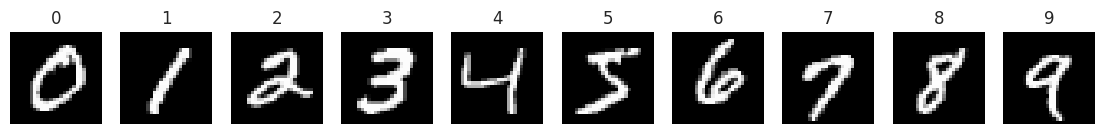

dígito,0,1,2,3,4,5,6,7,8,9
treino (%),9.87,11.24,9.93,10.22,9.74,9.04,9.86,10.44,9.75,9.91
teste (%),9.80,11.35,10.32,10.10,9.82,8.92,9.58,10.28,9.74,10.09


In [2]:
treino_original = datasets.MNIST(root="./data", train=True, download=True)
teste_original = datasets.MNIST(root="./data", train=False, download=True)
X_treino_completo, y_treino_completo = treino_original.data, treino_original.targets
X_teste_bruto, y_teste = teste_original.data, teste_original.targets
print(f"Treino: {tuple(X_treino_completo.shape)} | Teste: {tuple(X_teste_bruto.shape)} | "
      f"pixels de {X_treino_completo.min().item()} a {X_treino_completo.max().item()}")

fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for digito, ax in enumerate(axes):
    ax.imshow(X_treino_completo[y_treino_completo == digito][0].numpy(), cmap="gray")
    ax.set_title(str(digito))
    ax.axis("off")
plt.show()

display(pd.DataFrame(
    {
        "treino (%)": 100 * torch.bincount(y_treino_completo, minlength=10).numpy() / len(y_treino_completo),
        "teste (%)": 100 * torch.bincount(y_teste, minlength=10).numpy() / len(y_teste),
    },
    index=pd.Index(range(10), name="dígito"),
).T.round(2))

Os dígitos estão balanceados: cada um representa entre 8,9% e 11,4% das imagens. Por isso, a **acurácia** é uma boa medida para este problema.

As imagens são separadas em três grupos, cada um com uma função:

| Conjunto | Imagens | Papel | Analogia |
|---|---|---|---|
| **Treino** | 50.000 | A rede aprende com elas | Exercícios resolvidos |
| **Validação** | 10.000 | Comparamos configurações e escolhemos a melhor | Simulados |
| **Teste** | 10.000 | Medimos o resultado final | Prova final |

Se escolhêssemos a configuração olhando o teste, ele deixaria de representar dados novos, como um aluno que viu a prova antes. A validação existe para evitar isso. A divisão é **estratificada**: os três conjuntos mantêm a mesma proporção de cada dígito.

A normalização prepara as imagens para a rede:

- **Achatar:** a MLP recebe uma lista de números, não uma tabela. Cada imagem 28×28 vira uma lista de 784 valores. Com isso, a rede perde a noção de quais pixels são vizinhos, uma limitação que reaparece no tópico 5.
- **Padronizar:** os pixels saem da escala 0–255 e passam a ficar em torno de 0, com desvio-padrão 1, pela conta `(x − média) ÷ desvio`. Com números pequenos e equilibrados, nenhum valor "grita" mais alto que os outros nos cálculos, e o aprendizado fica mais rápido e estável.
- A média e o desvio-padrão vêm **só do treino**, como aconteceria na vida real com imagens novas.

In [3]:
idx_treino, idx_validacao = train_test_split(
    np.arange(len(y_treino_completo)), test_size=10_000, stratify=y_treino_completo.numpy(), random_state=SEED
)
idx_treino, idx_validacao = torch.from_numpy(idx_treino), torch.from_numpy(idx_validacao)


def achatar_e_escalar(imagens):
    """Cada imagem 28x28 vira um vetor de 784 valores entre 0 e 1."""
    return imagens.reshape(len(imagens), -1).float() / 255.0


X_treino_01 = achatar_e_escalar(X_treino_completo[idx_treino])
MEDIA, DESVIO = X_treino_01.mean().item(), X_treino_01.std().item()   # estatísticas só do treino


def preparar(imagens):
    """Achata, escala, padroniza com as estatísticas do treino e envia para a GPU."""
    return ((achatar_e_escalar(imagens) - MEDIA) / DESVIO).to(device)


X_treino, y_treino = preparar(X_treino_completo[idx_treino]), y_treino_completo[idx_treino].to(device)
X_validacao, y_validacao = preparar(X_treino_completo[idx_validacao]), y_treino_completo[idx_validacao].to(device)
X_teste, y_teste = preparar(X_teste_bruto), y_teste.to(device)

print(f"Treino: {len(y_treino):,} | Validação: {len(y_validacao):,} | Teste: {len(y_teste):,} | "
      f"entrada da rede: {X_treino.shape[1]} valores por imagem")
print(f"Estatísticas do treino: média {MEDIA:.4f} | desvio-padrão {DESVIO:.4f}")
print(f"Treino após padronizar: média {X_treino.mean().item():.4f} | desvio-padrão {X_treino.std().item():.4f}")

Treino: 50,000 | Validação: 10,000 | Teste: 10,000 | entrada da rede: 784 valores por imagem
Estatísticas do treino: média 0.1308 | desvio-padrão 0.3082
Treino após padronizar: média -0.0000 | desvio-padrão 1.0000


## Como a rede aprende

Uma MLP é formada por camadas de "neurônios". Cada neurônio faz uma conta simples: multiplica cada entrada por um **peso**, soma tudo com um valor extra (o **viés**, como o *b* de uma reta *y = ax + b*) e passa o resultado por uma **função de ativação**. Pesos e vieses são os **parâmetros**: os números que a rede ajusta para aprender. No início, eles são aleatórios.

| Peça | O que faz |
|---|---|
| **Camada de entrada** | Recebe os 784 pixels da imagem |
| **Camadas ocultas** | Transformam os pixels em padrões úteis (traços, curvas, partes de dígitos) |
| **ReLU** | Ativação que zera os valores negativos e mantém os positivos: `max(0, x)`. É ela que permite à rede aprender relações que não são linhas retas; sem ela, empilhar camadas equivaleria a uma única conta linear |
| **Camada de saída** | Dá uma pontuação para cada dígito de 0 a 9. A **softmax** transforma as pontuações em probabilidades que somam 100%, e a maior delas é a resposta |

O treino repete um ciclo de quatro passos:

1. **Prever:** a rede olha um **lote** de imagens (por exemplo, 64) e dá seus palpites.
2. **Medir o erro:** a **perda** (entropia cruzada) mede o quanto os palpites erraram. Ela é alta quando a rede dá pouca probabilidade ao dígito correto e chega a zero quando a rede acerta com total certeza. **Quanto menor a perda, melhor.**
3. **Calcular o gradiente:** para cada peso, o **gradiente** indica em que direção (aumentar ou diminuir) e com que força ele deve mudar para a perda cair. É como descer uma montanha no escuro sentindo a inclinação do chão com o pé. O cálculo é feito da saída para a entrada e se chama **retropropagação** (*backpropagation*).
4. **Ajustar os pesos:** o **otimizador** dá um passo na direção indicada. Usamos o **Adam**, que ajusta sozinho o passo de cada peso: acelera onde o caminho é consistente e freia onde os gradientes oscilam. O tamanho base desse passo é a **taxa de aprendizado** (*learning rate*).

Uma **época** é uma passagem completa pelas 50.000 imagens de treino. Ao fim de cada época, medimos a perda e a acurácia no treino e na validação, com a rede em **modo de avaliação**, que desliga as técnicas usadas só durante o treino (como o dropout do tópico 4).

In [4]:
class MLP(nn.Module):
    """MLP com camadas ocultas de mesma largura, ativação ReLU e Dropout opcional."""

    def __init__(self, camadas_ocultas=1, neuronios=128, dropout=0.0):
        super().__init__()
        camadas = []
        entrada = 28 * 28
        for _ in range(camadas_ocultas):
            camadas.append(nn.Linear(entrada, neuronios))
            camadas.append(nn.ReLU())
            if dropout > 0:
                camadas.append(nn.Dropout(dropout))
            entrada = neuronios
        camadas.append(nn.Linear(entrada, 10))
        self.rede = nn.Sequential(*camadas)

    def forward(self, x):
        return self.rede(x)


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)


def gerar_lotes(X, y, tamanho_lote, embaralhar=True, gerador=None):
    """Divide (X, y) em lotes; com embaralhar=True, a ordem muda a cada chamada."""
    n = len(y)
    if embaralhar:
        ordem = torch.randperm(n, generator=gerador).to(X.device)
    else:
        ordem = torch.arange(n, device=X.device)
    for inicio in range(0, n, tamanho_lote):
        idx = ordem[inicio:inicio + tamanho_lote]
        yield X[idx], y[idx]


@torch.no_grad()
def avaliar(modelo, X, y, tamanho_lote=4096):
    """Devolve a perda média, a acurácia e as previsões do modelo, em modo de avaliação."""
    modelo.eval()
    criterio = nn.CrossEntropyLoss(reduction="sum")
    perda_total, previsoes = 0.0, []
    for X_lote, y_lote in gerar_lotes(X, y, tamanho_lote, embaralhar=False):
        logits = modelo(X_lote)
        perda_total += criterio(logits, y_lote).item()
        previsoes.append(logits.argmax(dim=1))
    previsoes = torch.cat(previsoes)
    acuracia = (previsoes == y).float().mean().item()
    return perda_total / len(y), acuracia, previsoes


def treinar(camadas_ocultas=1, neuronios=128, taxa_aprendizado=1e-3, tamanho_lote=64,
            dropout=0.0, weight_decay=0.0, epocas=EPOCAS, seed=SEED):
    """Treina uma MLP com Adam e devolve o modelo, o histórico por época e o tempo gasto."""
    fixar_semente(seed)
    modelo = MLP(camadas_ocultas, neuronios, dropout).to(device)
    otimizador = torch.optim.Adam(modelo.parameters(), lr=taxa_aprendizado, weight_decay=weight_decay)
    criterio = nn.CrossEntropyLoss()
    gerador = torch.Generator().manual_seed(seed)

    historico = []
    inicio = time.time()
    for epoca in range(1, epocas + 1):
        modelo.train()
        soma = torch.zeros((), device=device)
        soma_quadrados = torch.zeros((), device=device)
        n_lotes = 0
        for X_lote, y_lote in gerar_lotes(X_treino, y_treino, tamanho_lote, gerador=gerador):
            otimizador.zero_grad()
            perda = criterio(modelo(X_lote), y_lote)
            perda.backward()
            otimizador.step()
            soma += perda.detach()
            soma_quadrados += perda.detach() ** 2
            n_lotes += 1

        media_lotes = soma / n_lotes
        desvio_lotes = torch.clamp(soma_quadrados / n_lotes - media_lotes ** 2, min=0).sqrt()
        perda_tr, acc_tr, _ = avaliar(modelo, X_treino, y_treino)
        perda_val, acc_val, _ = avaliar(modelo, X_validacao, y_validacao)
        historico.append({
            "epoca": epoca,
            "perda_lotes": media_lotes.item(),
            "desvio_perda_lotes": desvio_lotes.item(),
            "perda_treino": perda_tr,
            "acc_treino": acc_tr,
            "perda_validacao": perda_val,
            "acc_validacao": acc_val,
        })
    return modelo, pd.DataFrame(historico), time.time() - inicio

## Como medimos os resultados

Duas ideias guiam todas as análises:

- **Overfitting (sobreajuste):** a rede **decora** os exemplos de treino em vez de aprender a regra geral, como um aluno que memoriza as respostas dos exercícios e erra a prova. Sinal: acerta muito mais no treino do que na validação, e a perda de validação volta a subir.
- **Underfitting (subajuste):** a rede **não aprende** nem os exemplos de treino. Sinal: erra muito em todos os conjuntos.

Para medi-las, cada experimento é resumido nas métricas abaixo:

| Métrica | O que mostra |
|---|---|
| **Acurácia de treino, validação e teste** | Porcentagem de acertos em cada conjunto, ao final das 20 épocas |
| **Gap treino − teste (pp)** | Quanto a rede vai melhor no que já viu do que em dados novos. Gap alto indica overfitting |
| **Época da menor perda de validação** | Quando a rede estava no seu melhor em dados novos. Se for bem antes da época 20, ela piorou depois disso |
| **Aumento da perda de validação (%)** | Quanto a perda de validação subiu depois desse ponto. Subida alta indica overfitting |
| **Épocas até 97%** | Quantas épocas a rede levou para acertar 97% na validação. Mede a **convergência**, ou seja, a rapidez com que chega a uma solução estável |
| **Oscilação da validação (pp)** | Quanto a acurácia de validação varia nas 5 últimas épocas. Mede a **estabilidade** do treino |
| **Ruído entre lotes** | Quanto a perda varia de um lote para outro dentro de uma época. Outra medida de estabilidade |

**pp (pontos percentuais)** é a diferença direta entre duas porcentagens. Passar de 97% para 98% é um ganho de **1 pp**, e não de 1% (1% de 97% daria 97,97%).

Com essas métricas, cada experimento recebe um diagnóstico automático:

| Diagnóstico | Regra | Por quê |
|---|---|---|
| **não convergiu** | Acurácia de treino abaixo de 50% | A rede não aprendeu nada útil |
| **underfitting** | Acurácia de treino abaixo de 98% | Até a menor rede testada tem capacidade de passar de 99% no treino |
| **overfitting** | Gap treino − validação acima de 1 pp **e** perda de validação final mais de 10% acima do seu mínimo | Os dois sinais de memorização ao mesmo tempo (1 pp equivale a cerca de 100 imagens) |
| **overfitting leve** | Apenas um dos dois sinais | Memorização ainda fraca |
| **bom ajuste** | Nenhum dos sinais | A rede aprendeu sem decorar |

In [5]:
LIMIAR_UNDERFITTING = 0.98    # acurácia mínima esperada no treino
LIMIAR_GAP = 0.01             # 1 ponto percentual entre treino e validação
LIMIAR_AUMENTO_PERDA = 0.10   # perda de validação final 10% acima do seu mínimo


def diagnosticar(r):
    """Classifica o ajuste do modelo com as regras acima."""
    if not np.isfinite(r["perda_treino"]) or r["acc_treino"] < 0.5:
        return "não convergiu"
    if r["acc_treino"] < LIMIAR_UNDERFITTING:
        return "underfitting"
    gap = r["acc_treino"] - r["acc_validacao"]
    aumento = r["perda_validacao"] / r["perda_val_minima"] - 1
    sinais = int(gap > LIMIAR_GAP) + int(aumento > LIMIAR_AUMENTO_PERDA)
    return {0: "bom ajuste", 1: "overfitting leve", 2: "overfitting"}[sinais]


def principais_confusoes(matriz, n=3):
    """Lista os n pares (real, previsto, quantidade) com mais erros na matriz de confusão."""
    erros = matriz.copy()
    np.fill_diagonal(erros, 0)
    ordem = np.argsort(erros, axis=None)[::-1][:n]
    pares = [np.unravel_index(i, erros.shape) for i in ordem]
    return [(int(real), int(prev), int(erros[real, prev])) for real, prev in pares if erros[real, prev] > 0]


def texto_confusoes(matriz, n=3):
    return ", ".join(f"{real}→{prev} ({qtd})" for real, prev, qtd in principais_confusoes(matriz, n))


CONFIG_BASE = {
    "camadas_ocultas": 1,
    "neuronios": 128,
    "taxa_aprendizado": 1e-3,
    "tamanho_lote": 64,
    "dropout": 0.0,
    "weight_decay": 0.0,
}
RESULTADOS = {}


def executar_experimento(nome, grupo, **mudancas):
    """Treina a configuração CONFIG_BASE + mudancas, avalia e guarda o resultado em RESULTADOS."""
    config = {**CONFIG_BASE, **mudancas}
    modelo, historico, tempo = treinar(**config)
    perda_te, acc_te, previsoes = avaliar(modelo, X_teste, y_teste)
    matriz = confusion_matrix(y_teste.cpu().numpy(), previsoes.cpu().numpy(), labels=list(range(10)))

    final = historico.iloc[-1]
    perdas_val = historico["perda_validacao"]
    if perdas_val.notna().any():
        idx_min = perdas_val.idxmin()
        perda_val_min, epoca_min = perdas_val[idx_min], int(historico.loc[idx_min, "epoca"])
    else:
        perda_val_min, epoca_min = np.nan, np.nan
    atingiu_97 = historico.loc[historico["acc_validacao"] >= 0.97, "epoca"]

    r = {
        "nome": nome,
        "grupo": grupo,
        **config,
        "parametros": contar_parametros(modelo),
        "acc_treino": final["acc_treino"],
        "acc_validacao": final["acc_validacao"],
        "acc_teste": acc_te,
        "perda_treino": final["perda_treino"],
        "perda_validacao": final["perda_validacao"],
        "perda_teste": perda_te,
        "perda_val_minima": perda_val_min,
        "epoca_perda_val_minima": epoca_min,
        "epocas_ate_97": int(atingiu_97.iloc[0]) if len(atingiu_97) else np.nan,
        "oscilacao_val_pp": 100 * historico["acc_validacao"].tail(5).std(),
        "ruido_lotes": historico["desvio_perda_lotes"].tail(5).mean(),
        "tempo_por_epoca_s": tempo / len(historico),
        "modelo": modelo,
        "historico": historico,
        "matriz": matriz,
    }
    r["diagnostico"] = diagnosticar(r)
    RESULTADOS[nome] = r
    print(f"{nome:<28} treino {r['acc_treino']:.2%} | validação {r['acc_validacao']:.2%} | "
          f"teste {r['acc_teste']:.2%} | {tempo:5.1f}s | {r['diagnostico']}")
    return r


def resumo(r):
    """Uma linha de tabela com as métricas de um experimento."""
    return {
        "experimento": r["nome"],
        "grupo": r["grupo"],
        "camadas": r["camadas_ocultas"],
        "neurônios": r["neuronios"],
        "taxa de aprendizado": f"{r['taxa_aprendizado']:g}",
        "lote": r["tamanho_lote"],
        "dropout": f"{r['dropout']:g}",
        "L2": f"{r['weight_decay']:g}",
        "parâmetros": r["parametros"],
        "treino (%)": 100 * r["acc_treino"],
        "validação (%)": 100 * r["acc_validacao"],
        "teste (%)": 100 * r["acc_teste"],
        "gap treino−teste (pp)": 100 * (r["acc_treino"] - r["acc_teste"]),
        "época da menor perda de validação": r["epoca_perda_val_minima"],
        "aumento da perda de validação (%)": 100 * (r["perda_validacao"] / r["perda_val_minima"] - 1),
        "épocas até 97%": r["epocas_ate_97"],
        "oscilação da validação (pp)": r["oscilacao_val_pp"],
        "ruído entre lotes": r["ruido_lotes"],
        "tempo por época (s)": r["tempo_por_epoca_s"],
        "principais confusões (real→previsto)": texto_confusoes(r["matriz"]),
        "diagnóstico": r["diagnostico"],
    }


DECIMAIS = {
    "treino (%)": 2, "validação (%)": 2, "teste (%)": 2, "gap treino−teste (pp)": 2,
    "aumento da perda de validação (%)": 1, "oscilação da validação (pp)": 3,
    "ruído entre lotes": 4, "tempo por época (s)": 2,
}


def do_grupo(grupo):
    return [r for r in RESULTADOS.values() if r["grupo"] == grupo]


def dados(grupo=None):
    """Métricas de uma parte (ou de todos os experimentos) em um DataFrame."""
    resultados = RESULTADOS.values() if grupo is None else do_grupo(grupo)
    df = pd.DataFrame([resumo(r) for r in resultados])
    for coluna in ["época da menor perda de validação", "épocas até 97%"]:
        df[coluna] = df[coluna].astype("Int64")   # épocas são inteiros; vazio quando não existe
    return df


def tabela(grupo, colunas):
    """Tabela formatada com as colunas escolhidas de uma parte."""
    return dados(grupo)[["experimento", *colunas]].round(DECIMAIS)


def melhor_do_grupo(grupo):
    return max(do_grupo(grupo), key=lambda r: r["acc_validacao"])


def plotar_matriz_confusao(matriz, titulo, ax, fonte=8):
    """Matriz de confusão: acertos na diagonal (azul) e erros em vermelho, mais escuro quanto mais frequente."""
    erros = matriz.astype(float)
    np.fill_diagonal(erros, np.nan)
    rotulos = np.where(matriz > 0, matriz.astype(str), "")
    sns.heatmap(erros, ax=ax, cmap="Reds", vmin=0, annot=rotulos, fmt="", annot_kws={"size": fonte},
                cbar=False, square=True, linewidths=0.5, linecolor="white")
    for i in range(10):
        ax.text(i + 0.5, i + 0.5, str(matriz[i, i]), ha="center", va="center",
                fontsize=fonte, color="#1f4e79", fontweight="bold")
    ax.set_facecolor("#dbe8f5")
    ax.grid(False)
    ax.set_xlabel("dígito previsto")
    ax.set_ylabel("dígito real")
    ax.set_title(titulo, fontsize=fonte + 2)


def plotar_grade_matrizes(resultados, titulo, n_colunas=4, fonte=7):
    """Matrizes de confusão de vários experimentos lado a lado."""
    n_linhas = int(np.ceil(len(resultados) / n_colunas))
    fig, axes = plt.subplots(n_linhas, n_colunas, figsize=(4.3 * n_colunas, 4.5 * n_linhas))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes:
        ax.axis("off")
    for ax, r in zip(axes, resultados):
        ax.axis("on")
        plotar_matriz_confusao(r["matriz"], f"{r['nome']}\nteste: {r['acc_teste']:.2%}", ax, fonte)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


def plotar_curvas(r, titulo):
    """Perda e acurácia de treino e validação ao longo das épocas."""
    h = r["historico"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(h["epoca"], h["perda_treino"], marker="o", label="treino")
    axes[0].plot(h["epoca"], h["perda_validacao"], marker="o", label="validação")
    if np.isfinite(r["epoca_perda_val_minima"]):
        axes[0].axvline(r["epoca_perda_val_minima"], color="gray", linestyle="--",
                        label=f"menor perda de validação (época {r['epoca_perda_val_minima']})")
    axes[0].set(title="Perda (entropia cruzada)", xlabel="época", ylabel="perda")
    axes[1].plot(h["epoca"], 100 * h["acc_treino"], marker="o", label="treino")
    axes[1].plot(h["epoca"], 100 * h["acc_validacao"], marker="o", label="validação")
    axes[1].set(title="Acurácia", xlabel="época", ylabel="acurácia (%)")
    for ax in axes:
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

## Baseline e acurácia inicial

O baseline é a versão mais simples **razoável** de uma MLP. Cada escolha tem um motivo:

| Escolha | Valor | Por quê |
|---|---|---|
| Entrada | 784 neurônios | Um para cada pixel da imagem 28×28 |
| Camadas ocultas | 1 | A menor rede que já aprende relações não lineares. Sem camada oculta, o modelo seria uma conta linear, que costuma ficar perto de 92% no MNIST |
| Neurônios na camada oculta | 128 | Valor intermediário da faixa testada no tópico 2 (64 a 512): pequeno e rápido, mas com folga para aprender |
| Saída | 10 neurônios | Um para cada dígito |
| Parâmetros | 101.770 | 784 × 128 pesos + 128 vieses na camada oculta, e 128 × 10 + 10 na saída |
| Otimizador | Adam, taxa 0,001 | Visto em aula e funciona bem sem ajuste fino. 0,001 é o valor recomendado pelos criadores do Adam |
| Tamanho do lote | 64 imagens | Meio-termo comum entre velocidade e precisão de cada passo, dentro da faixa testada no tópico 3 |
| Regularização | Nenhuma | O baseline precisa ser o modelo "puro", para o tópico 4 medir o efeito de cada técnica |
| Épocas | 20 | Suficiente para a rede convergir e para o overfitting aparecer, se houver. Todos os experimentos usam as mesmas 20 épocas, para uma comparação justa |

baseline 1×128               treino 99.59% | validação 97.29% | teste 97.61% |  20.7s | overfitting

Acurácia inicial no teste: 97.61% | 101,770 parâmetros


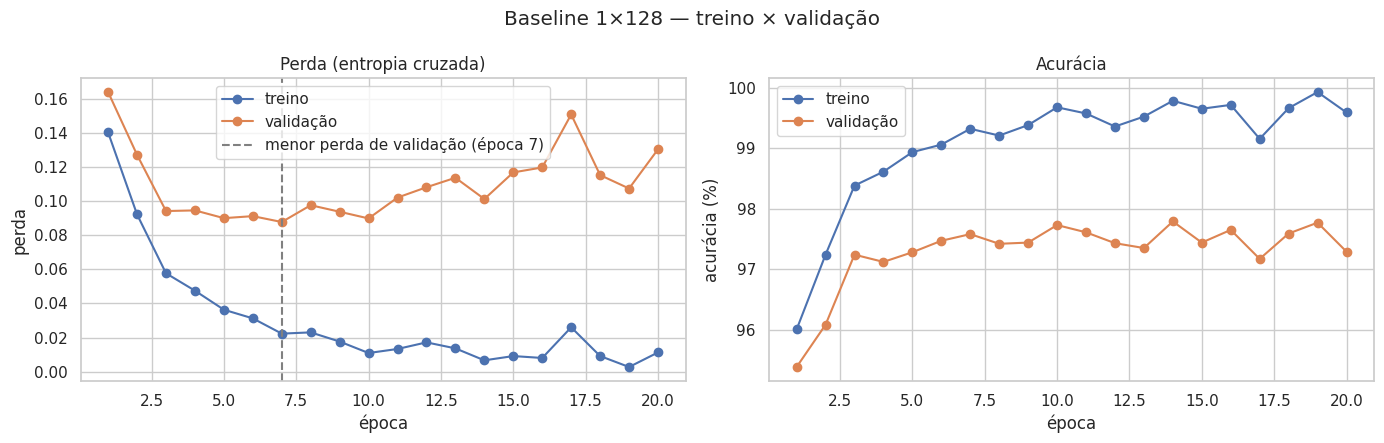

In [6]:
baseline = executar_experimento("baseline 1×128", "base")
print(f"\nAcurácia inicial no teste: {baseline['acc_teste']:.2%} | {contar_parametros(baseline['modelo']):,} parâmetros")
plotar_curvas(baseline, "Baseline 1×128 — treino × validação")

**Como ler o gráfico:** à esquerda, a perda (o erro) no treino e na validação a cada época; à direita, a acurácia. A linha tracejada marca a época em que a perda de validação foi a menor.

**Quanto do resultado é sorte?** Os pesos começam aleatórios e a ordem dos lotes é sorteada, então treinar a mesma rede duas vezes dá resultados um pouco diferentes. Para medir essa variação, repetimos o baseline com três **sementes** (números que fixam os sorteios). O desvio-padrão entre as três execuções vira nossa **régua de ruído**: nos próximos tópicos, diferenças menores que 2 desvios-padrão na validação são tratadas como **empate**, porque podem ser apenas sorte.

In [7]:
variacao = []
for seed in [42, 7, 123]:
    modelo, historico, _ = treinar(**CONFIG_BASE, seed=seed)
    _, acc_te, _ = avaliar(modelo, X_teste, y_teste)
    variacao.append({
        "semente": seed,
        "validação (%)": 100 * historico["acc_validacao"].iloc[-1],
        "teste (%)": 100 * acc_te,
    })
variacao = pd.DataFrame(variacao)
display(variacao.round(2))

RUIDO_PP = variacao["validação (%)"].std()
print(f"Desvio-padrão entre sementes: validação {RUIDO_PP:.3f} pp | teste {variacao['teste (%)'].std():.3f} pp")
print(f"Régua de ruído (2 desvios-padrão na validação): {2 * RUIDO_PP:.2f} pp")

,semente,validação (%),teste (%)
0,42,97.29,97.61
1,7,97.59,97.38
2,123,97.81,97.66


Desvio-padrão entre sementes: validação 0.261 pp | teste 0.149 pp
Régua de ruído (2 desvios-padrão na validação): 0.52 pp


## Conclusão do tópico 1

- **Acurácia inicial: 97,61% no teste**, ou 239 erros em 10.000 imagens. Até uma rede pequena acerta quase tudo, porque o MNIST é um problema "fácil" para uma MLP. A consequência é que as melhorias possíveis são pequenas (faltam só 2,39 pp para 100%) e precisam ser comparadas com cuidado.
- **O baseline já decora o treino.** Ele acerta 99,59% das imagens de treino contra 97,61% no teste (gap de 1,98 pp). No gráfico, a perda de validação cai até a época 7 e depois **sobe 49%**, enquanto a de treino continua caindo. A acurácia quase não muda, porque a perda pune com força os erros cometidos com muita certeza: da época 7 em diante, a rede passa a errar com cada vez mais convicção.
- **Isso não torna o baseline inconclusivo.** Ele cumpre seu papel de referência, e o overfitting já é um primeiro achado. Treinar por mais épocas não ajudaria, e surgem duas perguntas para os próximos tópicos: redes maiores decoram ainda mais (tópico 2)? A regularização controla isso (tópico 4)?
- **Régua de ruído: 0,52 pp.** Só de trocar a semente, a validação variou de 97,29% a 97,81%. Diferenças menores que 0,52 pp entre experimentos não provam que uma configuração é melhor.

# 2. Variação da Arquitetura

**Por que este tópico?** O baseline tem uma única camada de 128 neurônios. Aqui descobrimos se uma rede maior aprende melhor e a partir de que tamanho deixa de valer a pena.

Testamos 1, 2 e 3 camadas ocultas com 64, 128, 256 e 512 neurônios cada: **12 arquiteturas**, com taxa de aprendizado, lote e ausência de regularização iguais às do baseline. A notação `MLP 2×256` significa 2 camadas de 256 neurônios.

- **Largura:** mais neurônios permitem representar mais padrões ao mesmo tempo.
- **Profundidade:** camadas a mais combinam padrões simples (traços) em padrões compostos (partes de dígitos).

Nos dois casos, aumentam os parâmetros e, portanto, a **capacidade** da rede, o que também aumenta a facilidade de decorar o treino.

In [8]:
for camadas in [1, 2, 3]:
    for neuronios in [64, 128, 256, 512]:
        executar_experimento(f"MLP {camadas}×{neuronios}", "arquitetura",
                             camadas_ocultas=camadas, neuronios=neuronios)

MLP 1×64                     treino 99.75% | validação 97.24% | teste 97.46% |  20.7s | overfitting
MLP 1×128                    treino 99.59% | validação 97.29% | teste 97.61% |  19.6s | overfitting
MLP 1×256                    treino 99.85% | validação 97.88% | teste 97.95% |  20.7s | overfitting
MLP 1×512                    treino 99.61% | validação 97.82% | teste 97.97% |  23.0s | overfitting
MLP 2×64                     treino 99.55% | validação 97.20% | teste 97.25% |  23.0s | overfitting
MLP 2×128                    treino 99.73% | validação 97.77% | teste 97.66% |  23.4s | overfitting
MLP 2×256                    treino 99.62% | validação 97.78% | teste 97.97% |  24.7s | overfitting
MLP 2×512                    treino 99.73% | validação 97.94% | teste 98.00% |  24.2s | overfitting
MLP 3×64                     treino 99.61% | validação 97.42% | teste 97.45% |  26.7s | overfitting
MLP 3×128                    treino 99.55% | validação 97.52% | teste 97.78% |  26.3s | overfitting


In [9]:
display(tabela("arquitetura", [
    "camadas", "neurônios", "parâmetros", "treino (%)", "validação (%)", "teste (%)",
    "gap treino−teste (pp)", "época da menor perda de validação", "tempo por época (s)", "diagnóstico",
]))

melhor_arq = melhor_do_grupo("arquitetura")
ARQUITETURA = {"camadas_ocultas": melhor_arq["camadas_ocultas"], "neuronios": melhor_arq["neuronios"]}
print(f"Arquitetura escolhida pela validação: {melhor_arq['nome']} | validação {melhor_arq['acc_validacao']:.2%} | "
      f"{melhor_arq['parametros']:,} parâmetros")

,experimento,camadas,neurônios,parâmetros,treino (%),validação (%),teste (%),gap treino−teste (pp),época da menor perda de validação,tempo por época (s),diagnóstico
0,MLP 1×64,1,64,50890,99.75,97.24,97.46,2.29,8,1.03,overfitting
1,MLP 1×128,1,128,101770,99.59,97.29,97.61,1.98,7,0.98,overfitting
2,MLP 1×256,1,256,203530,99.85,97.88,97.95,1.90,4,1.04,overfitting
3,MLP 1×512,1,512,407050,99.61,97.82,97.97,1.64,3,1.15,overfitting
4,MLP 2×64,2,64,55050,99.55,97.20,97.25,2.30,8,1.15,overfitting
5,MLP 2×128,2,128,118282,99.73,97.77,97.66,2.07,5,1.17,overfitting
6,MLP 2×256,2,256,269322,99.62,97.78,97.97,1.65,6,1.24,overfitting
7,MLP 2×512,2,512,669706,99.73,97.94,98.00,1.73,3,1.21,overfitting
8,MLP 3×64,3,64,59210,99.61,97.42,97.45,2.16,5,1.33,overfitting
9,MLP 3×128,3,128,134794,99.55,97.52,97.78,1.77,5,1.31,overfitting


Arquitetura escolhida pela validação: MLP 2×512 | validação 97.94% | 669,706 parâmetros


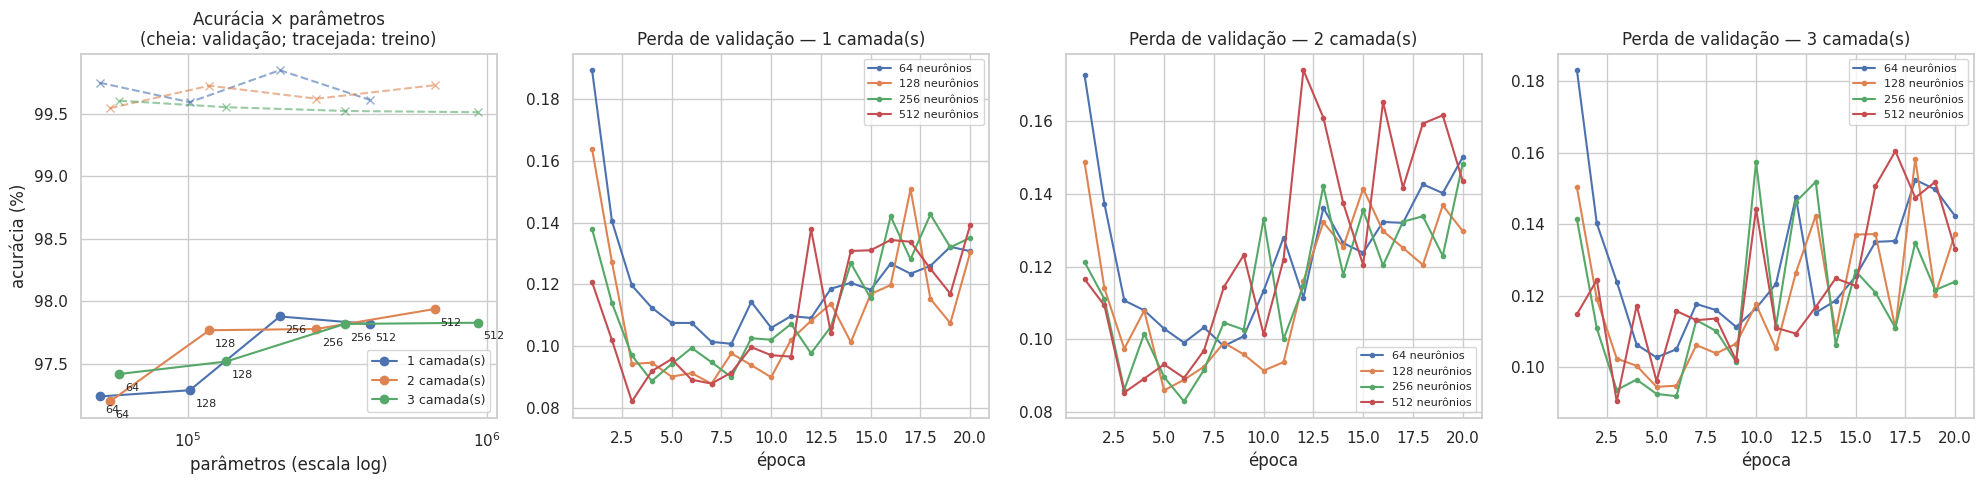

In [10]:
arq = dados("arquitetura")
fig = plt.figure(figsize=(20, 5))
ax = fig.add_subplot(1, 4, 1)
for camadas, grupo_df in arq.groupby("camadas"):
    grupo_df = grupo_df.sort_values("parâmetros")
    linha = ax.plot(grupo_df["parâmetros"], grupo_df["validação (%)"], marker="o", label=f"{camadas} camada(s)")[0]
    ax.plot(grupo_df["parâmetros"], grupo_df["treino (%)"], marker="x", linestyle="--", color=linha.get_color(), alpha=0.6)
    for _, ponto in grupo_df.iterrows():
        ax.annotate(f"{ponto['neurônios']}", (ponto["parâmetros"], ponto["validação (%)"]),
                    textcoords="offset points", xytext=(4, -12), fontsize=8)
ax.set_xscale("log")
ax.set(xlabel="parâmetros (escala log)", ylabel="acurácia (%)", title="Acurácia × parâmetros\n(cheia: validação; tracejada: treino)")
ax.legend(fontsize=9)

for coluna, camadas in enumerate([1, 2, 3], start=2):
    ax = fig.add_subplot(1, 4, coluna)
    for r in do_grupo("arquitetura"):
        if r["camadas_ocultas"] == camadas:
            ax.plot(r["historico"]["epoca"], r["historico"]["perda_validacao"], marker=".", label=f"{r['neuronios']} neurônios")
    ax.set(title=f"Perda de validação — {camadas} camada(s)", xlabel="época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Como ler os gráficos, da esquerda para a direita:**

1. **Acurácia × parâmetros:** cada ponto é uma arquitetura, e o número ao lado indica os neurônios por camada. A linha cheia é a validação e a tracejada, o treino. O eixo horizontal está em escala logarítmica porque o número de parâmetros cresce muito. Se a linha de validação fica plana enquanto a rede cresce, chegamos à **saturação**: a rede ficou maior sem acertar mais.
2. **Perda de validação com 1 camada**, 3. **com 2 camadas** e 4. **com 3 camadas:** uma linha para cada largura. Como a perda mede o erro, **quanto menor, melhor**. O formato em "U" (cai, atinge um mínimo e volta a subir) é a marca do overfitting: depois do fundo do "U", a rede passou a decorar o treino.

## Conclusão do tópico 2

- **Largura ajuda, até certo ponto.** Com 1 camada, passar de 64 para 256 neurônios elevou a validação de 97,24% para 97,88% (+0,64 pp, acima da régua de 0,52 pp). De 256 para 512 neurônios, a mudança ficou entre −0,06 e +0,16 pp: empate.
- **Profundidade não ajudou.** Com a mesma largura, 1, 2 ou 3 camadas diferem no máximo 0,48 pp, sempre dentro da régua. E cada camada a mais custa tempo: cerca de 1,0 s por época com 1 camada e 1,3 s com 3. Como a MLP recebe os pixels "achatados", uma camada larga já extrai quase tudo o que eles oferecem.
- **Todas as redes decoraram o treino.** Elas acertaram de 99,5% a 99,9% no treino, contra 97,2% a 97,9% na validação. As maiores decoram mais cedo: com 512 neurônios, o fundo do "U" chega na época 3, contra as épocas 5 a 8 com 64. Mais capacidade significa mais facilidade para memorizar.
- **Escolha:** pela regra de maior validação, seguimos com a **MLP 2×512** (97,94%). A MLP 1×256 fica a só 0,06 pp com um terço dos parâmetros, o que é um empate técnico. Mantivemos a regra para não escolher "olhando o resultado".

# 3. Hiperparâmetros de Treinamento

**Por que este tópico?** O tópico 2 definiu o tamanho da rede. Agora mudamos a **forma de treinar**, mantendo a MLP 2×512. Dois "botões" controlam o aprendizado:

- **Taxa de aprendizado (0,1; 0,01; 0,001): o tamanho do passo.** Voltando à descida da montanha no escuro: passos grandes descem rápido, mas podem passar do vale e ficar pulando de uma encosta para a outra, ou até subir em vez de descer (**divergir**). Passos pequenos são seguros, mas lentos.
- **Tamanho do lote (32, 64, 128, 256): quantas imagens a rede vê antes de cada passo.** Com mais imagens, a direção do passo é mais confiável, mas há menos passos por época: são 50.000 ÷ 32 ≈ 1.563 passos com lote 32, contra 50.000 ÷ 256 ≈ 196 com lote 256. Com poucas imagens, a direção fica "tremida".

Os dois botões interagem: um passo grande em uma direção tremida é a pior combinação. Por isso, testamos todas as 3 × 4 = **12 combinações**, observando os três aspectos pedidos:

| Aspecto | Pergunta | Como medimos |
|---|---|---|
| **Convergência** | A rede chega a uma solução? Com que rapidez? | Épocas até 97% de acerto na validação |
| **Estabilidade** | O aprendizado é suave ou aos solavancos? | Oscilação da validação entre épocas e ruído da perda entre lotes |
| **Desempenho final** | Quanto ela acerta no fim? | Acurácia de validação e de teste na época 20 |

In [11]:
TAXAS = [0.1, 0.01, 0.001]
LOTES = [32, 64, 128, 256]
for taxa in TAXAS:
    for lote in LOTES:
        executar_experimento(f"lr {taxa:g} · lote {lote}", "treinamento", **ARQUITETURA,
                             taxa_aprendizado=taxa, tamanho_lote=lote)

lr 0.1 · lote 32             treino 10.44% | validação 10.44% | teste 10.28% |  47.4s | não convergiu
lr 0.1 · lote 64             treino 9.91% | validação 9.92% | teste 10.09% |  23.7s | não convergiu
lr 0.1 · lote 128            treino 9.88% | validação 9.87% | teste 9.59% |  12.1s | não convergiu
lr 0.1 · lote 256            treino 9.87% | validação 9.86% | teste 9.59% |   6.4s | não convergiu
lr 0.01 · lote 32            treino 96.11% | validação 94.47% | teste 94.70% |  47.1s | underfitting
lr 0.01 · lote 64            treino 97.11% | validação 95.71% | teste 95.69% |  23.6s | underfitting
lr 0.01 · lote 128           treino 98.03% | validação 96.47% | teste 96.59% |  12.2s | overfitting leve
lr 0.01 · lote 256           treino 98.56% | validação 96.67% | teste 96.65% |   6.2s | overfitting
lr 0.001 · lote 32           treino 99.62% | validação 97.81% | teste 97.81% |  46.7s | overfitting
lr 0.001 · lote 64           treino 99.73% | validação 97.94% | teste 98.00% |  23.8s | overf

In [12]:
display(tabela("treinamento", [
    "taxa de aprendizado", "lote", "treino (%)", "validação (%)", "teste (%)", "gap treino−teste (pp)",
    "épocas até 97%", "oscilação da validação (pp)", "ruído entre lotes", "tempo por época (s)", "diagnóstico",
]))

melhor_treino = melhor_do_grupo("treinamento")
CONFIG_TREINO = {
    **ARQUITETURA,
    "taxa_aprendizado": melhor_treino["taxa_aprendizado"],
    "tamanho_lote": melhor_treino["tamanho_lote"],
}
print(f"Combinação escolhida pela validação: {melhor_treino['nome']} | validação {melhor_treino['acc_validacao']:.2%}")

,experimento,taxa de aprendizado,lote,treino (%),validação (%),teste (%),gap treino−teste (pp),épocas até 97%,oscilação da validação (pp),ruído entre lotes,tempo por época (s),diagnóstico
0,lr 0.1 · lote 32,0.1,32,10.44,10.44,10.28,0.16,<NA>,0.569,0.0305,2.37,não convergiu
1,lr 0.1 · lote 64,0.1,64,9.91,9.92,10.09,-0.18,<NA>,0.720,0.0180,1.19,não convergiu
2,lr 0.1 · lote 128,0.1,128,9.88,9.87,9.59,0.29,<NA>,0.740,0.0112,0.60,não convergiu
3,lr 0.1 · lote 256,0.1,256,9.87,9.86,9.59,0.28,<NA>,0.598,0.0071,0.32,não convergiu
4,lr 0.01 · lote 32,0.01,32,96.11,94.47,94.70,1.41,<NA>,0.760,0.1909,2.36,underfitting
5,lr 0.01 · lote 64,0.01,64,97.11,95.71,95.69,1.42,<NA>,0.389,0.1030,1.18,underfitting
6,lr 0.01 · lote 128,0.01,128,98.03,96.47,96.59,1.44,<NA>,0.220,0.0627,0.61,overfitting leve
7,lr 0.01 · lote 256,0.01,256,98.56,96.67,96.65,1.91,<NA>,0.176,0.0400,0.31,overfitting
8,lr 0.001 · lote 32,0.001,32,99.62,97.81,97.81,1.81,3,0.174,0.0688,2.33,overfitting
9,lr 0.001 · lote 64,0.001,64,99.73,97.94,98.00,1.73,3,0.218,0.0352,1.19,overfitting


Combinação escolhida pela validação: lr 0.001 · lote 256 | validação 98.13%


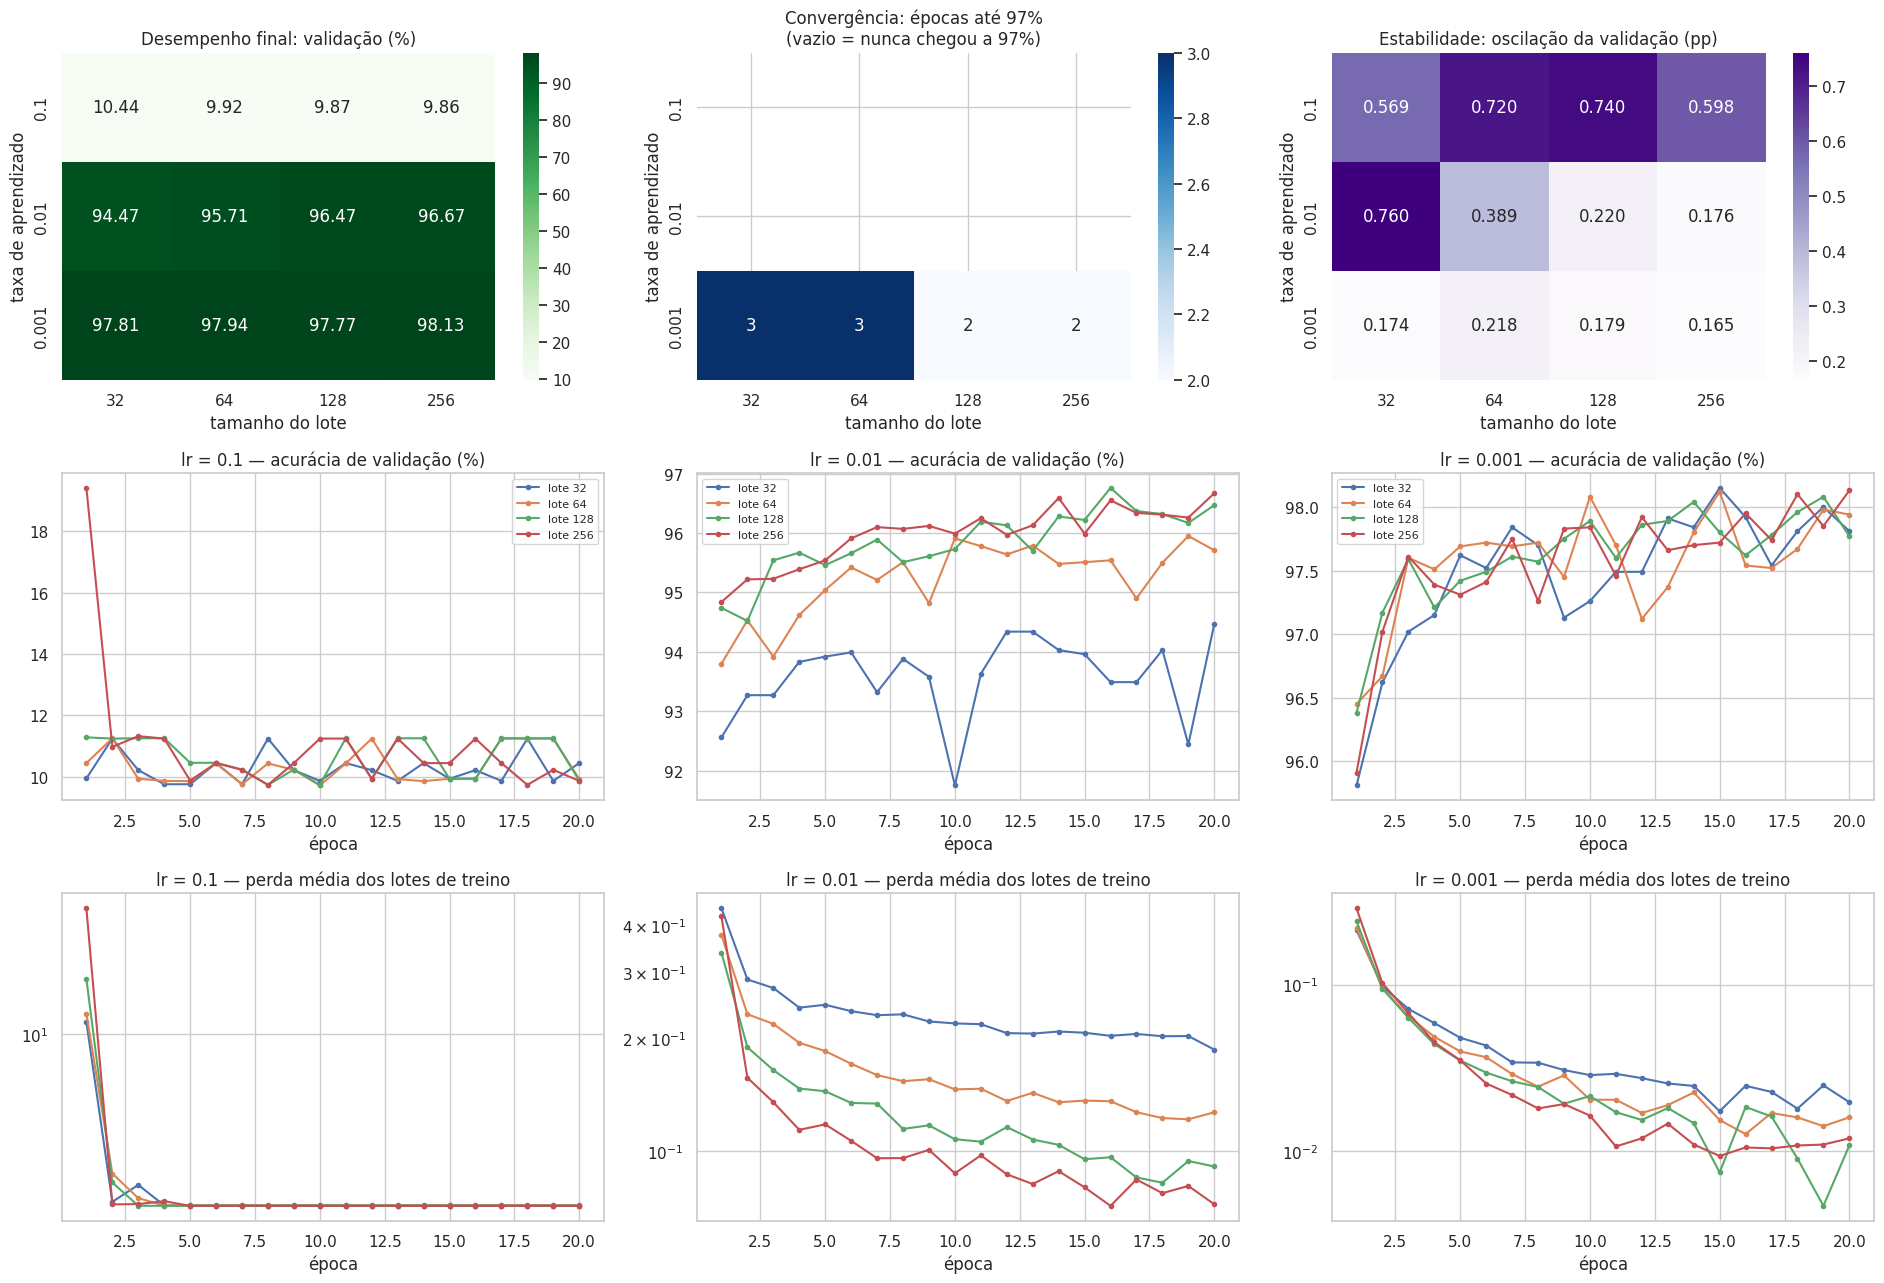

In [13]:
trein = dados("treinamento")
fig, axes = plt.subplots(3, 3, figsize=(19, 13))
mapas = [
    ("validação (%)", "Desempenho final: validação (%)", "Greens", ".2f"),
    ("épocas até 97%", "Convergência: épocas até 97%\n(vazio = nunca chegou a 97%)", "Blues", ".0f"),
    ("oscilação da validação (pp)", "Estabilidade: oscilação da validação (pp)", "Purples", ".3f"),
]
for ax, (coluna, titulo, cores, formato) in zip(axes[0], mapas):
    grade = trein.pivot(index="taxa de aprendizado", columns="lote", values=coluna).astype(float)
    grade = grade.reindex([f"{taxa:g}" for taxa in TAXAS])
    sns.heatmap(grade, annot=True, fmt=formato, cmap=cores, ax=ax)
    ax.set(title=titulo, xlabel="tamanho do lote", ylabel="taxa de aprendizado")

for coluna, taxa in enumerate(TAXAS):
    for r in do_grupo("treinamento"):
        if r["taxa_aprendizado"] == taxa:
            h = r["historico"]
            axes[1, coluna].plot(h["epoca"], 100 * h["acc_validacao"], marker=".", label=f"lote {r['tamanho_lote']}")
            axes[2, coluna].plot(h["epoca"], h["perda_lotes"], marker=".", label=f"lote {r['tamanho_lote']}")
    axes[1, coluna].set(title=f"lr = {taxa:g} — acurácia de validação (%)", xlabel="época")
    axes[2, coluna].set(title=f"lr = {taxa:g} — perda média dos lotes de treino", xlabel="época", yscale="log")
    axes[1, coluna].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Como ler os gráficos:**

- **Primeira linha (mapas de calor):** cada quadrado é uma combinação; as linhas são a taxa de aprendizado e as colunas, o tamanho do lote. Da esquerda para a direita: **desempenho final** (mais verde = acerta mais), **convergência** (épocas até 97%; mais claro = mais rápido; vazio = nunca chegou a 97%) e **estabilidade** (oscilação; mais claro = mais estável).
- **Segunda linha:** a acurácia de validação a cada época. Há uma coluna por taxa de aprendizado e uma linha colorida por lote. Curvas que sobem rápido e ficam lisas mostram boa convergência e estabilidade; curvas serrilhadas mostram instabilidade.
- **Terceira linha:** a perda média dos lotes de treino, em escala logarítmica. Curva descendo significa que a rede está aprendendo; curva travada, que os passos são grandes demais para o aprendizado avançar.

## Conclusão do tópico 3

- **Taxa 0,1: o passo é grande demais e a rede diverge.** A perda explode na primeira época e trava. A rede passa a responder o mesmo dígito para todas as imagens e acerta só ~10%, o mesmo que chutar. Para o Adam, 0,1 é 100 vezes o valor recomendado.
- **Taxa 0,01: aprende, mas aos solavancos.** A validação fica entre 94,5% e 96,7% e nunca chega a 97%. Aqui o lote faz muita diferença. Com lote 256, a direção mais confiável compensa parte do passo grande (96,7%, oscilação de 0,18 pp). Com lote 32, os dois problemas se somam (94,5%, oscilação de 0,76 pp).
- **Taxa 0,001: converge com qualquer lote.** A validação chega a 97% em 2 ou 3 épocas e termina entre 97,77% e 98,13% (empate pela régua). O lote passa a influenciar a estabilidade e o tempo: com 256, a perda varia 6 vezes menos de um lote para outro, e cada época leva 0,30 s em vez de 2,29 s, porque a GPU processa as imagens de um lote em paralelo.
- **Escolha: taxa 0,001 com lote 256.** Teve a melhor validação (98,13%), foi a combinação mais estável e está entre as mais rápidas. A principal lição: **a taxa de aprendizado é o hiperparâmetro mais crítico.** Errar a taxa custou até 88 pp; errar o lote, no máximo 2,2 pp.

# 4. Regularização

**Por que este tópico?** Os tópicos 1 a 3 mostraram que todas as redes que aprenderam também decoraram o treino (overfitting). **Regularizar** é limitar essa memorização, para que a rede aprenda a regra geral em vez dos detalhes de cada exemplo. Mantemos a configuração escolhida (MLP 2×512, taxa 0,001, lote 256) e testamos duas técnicas:

- **Dropout:** em cada lote do treino, uma fração dos neurônios (20%, 50%...) é desligada ao acaso. É como um time em que, a cada treino, alguns jogadores faltam: ninguém pode depender de um único craque, e o conhecimento se espalha pelo time. Na avaliação, todos voltam a jogar.
- **L2 (*weight decay*):** soma ao erro uma "multa" proporcional ao tamanho dos pesos (λ·Σw², em que λ é a força da multa). Pesos grandes deixam a rede sensível demais aos detalhes de cada imagem; pesos menores produzem respostas mais suaves, que valem para mais casos.

Regularizar é uma questão de dose. Com pouca, a rede continua decorando; com demais, ela não consegue aprender nem o treino (**underfitting**). Por isso, testamos intensidades moderadas, uma combinação das duas técnicas e duas intensidades **excessivas, de propósito**, para mostrar o underfitting na prática.

| Situação | Acerto no treino | Acerto na validação | Curvas de perda |
|---|---|---|---|
| **Overfitting** | Muito alto | Bem abaixo do treino | A de treino cai e a de validação sobe |
| **Bom ajuste** | Alto | Perto do treino | As duas caem e se estabilizam juntas |
| **Underfitting** | Baixo | Baixo, perto do treino | As duas ficam altas |

In [14]:
REGULARIZACOES = {
    "sem regularização": {},
    "dropout 0.2": {"dropout": 0.2},
    "dropout 0.5": {"dropout": 0.5},
    "L2 1e-4": {"weight_decay": 1e-4},
    "L2 1e-3": {"weight_decay": 1e-3},
    "dropout 0.2 + L2 1e-4": {"dropout": 0.2, "weight_decay": 1e-4},
    "dropout 0.8 (excessivo)": {"dropout": 0.8},
    "L2 1e-2 (excessivo)": {"weight_decay": 1e-2},
}
for nome, regularizacao in REGULARIZACOES.items():
    executar_experimento(nome, "regularizacao", **CONFIG_TREINO, **regularizacao)

sem regularização            treino 99.88% | validação 98.13% | teste 98.23% |   6.3s | overfitting
dropout 0.2                  treino 99.80% | validação 98.05% | teste 98.02% |   6.8s | overfitting
dropout 0.5                  treino 99.47% | validação 98.05% | teste 97.94% |   6.9s | overfitting
L2 1e-4                      treino 99.70% | validação 98.00% | teste 97.91% |   6.8s | overfitting
L2 1e-3                      treino 99.35% | validação 97.91% | teste 97.78% |   6.7s | overfitting leve
dropout 0.2 + L2 1e-4        treino 99.76% | validação 98.12% | teste 98.20% |   7.0s | overfitting
dropout 0.8 (excessivo)      treino 97.89% | validação 97.01% | teste 97.10% |   6.7s | underfitting
L2 1e-2 (excessivo)          treino 96.63% | validação 95.98% | teste 96.50% |   6.5s | underfitting


In [15]:
display(tabela("regularizacao", [
    "dropout", "L2", "treino (%)", "validação (%)", "teste (%)", "gap treino−teste (pp)",
    "época da menor perda de validação", "aumento da perda de validação (%)", "diagnóstico",
]))

modelo_final = melhor_do_grupo("regularizacao")
print(f"Modelo final (maior validação): {modelo_final['nome']} | validação {modelo_final['acc_validacao']:.2%} | "
      f"teste {modelo_final['acc_teste']:.2%}")

,experimento,dropout,L2,treino (%),validação (%),teste (%),gap treino−teste (pp),época da menor perda de validação,aumento da perda de validação (%),diagnóstico
0,sem regularização,0,0,99.88,98.13,98.23,1.65,3,27.6,overfitting
1,dropout 0.2,0.2,0,99.80,98.05,98.02,1.78,7,26.4,overfitting
2,dropout 0.5,0.5,0,99.47,98.05,97.94,1.53,11,16.4,overfitting
3,L2 1e-4,0,0.0001,99.70,98.00,97.91,1.79,7,23.4,overfitting
4,L2 1e-3,0,0.001,99.35,97.91,97.78,1.57,19,8.5,overfitting leve
5,dropout 0.2 + L2 1e-4,0.2,0.0001,99.76,98.12,98.20,1.56,12,11.0,overfitting
6,dropout 0.8 (excessivo),0.8,0,97.89,97.01,97.10,0.79,19,0.3,underfitting
7,L2 1e-2 (excessivo),0,0.01,96.63,95.98,96.50,0.13,10,5.6,underfitting


Modelo final (maior validação): sem regularização | validação 98.13% | teste 98.23%


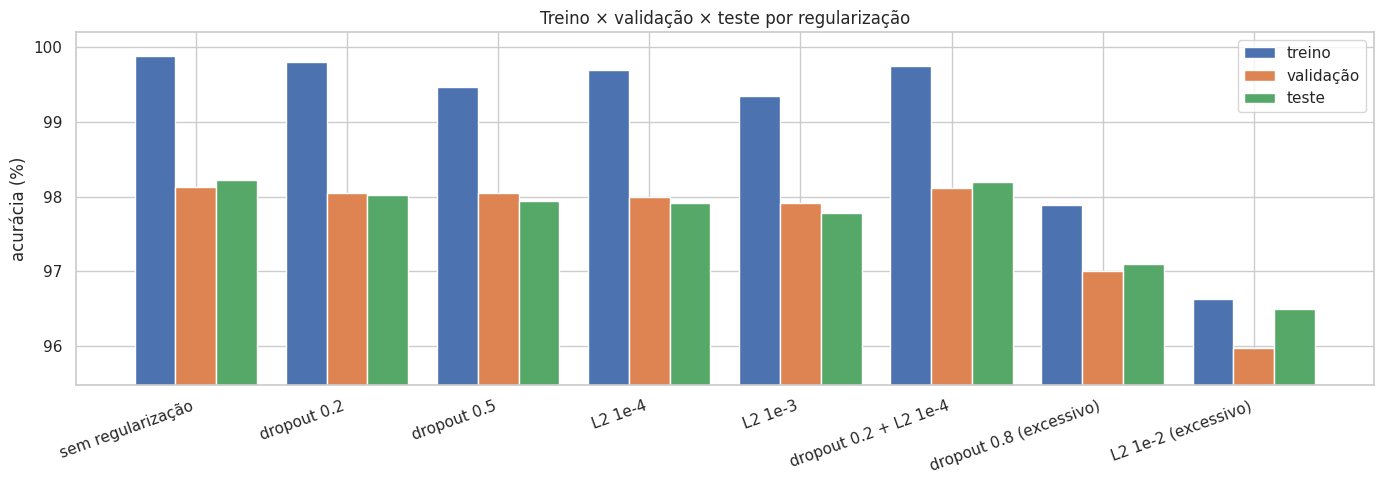

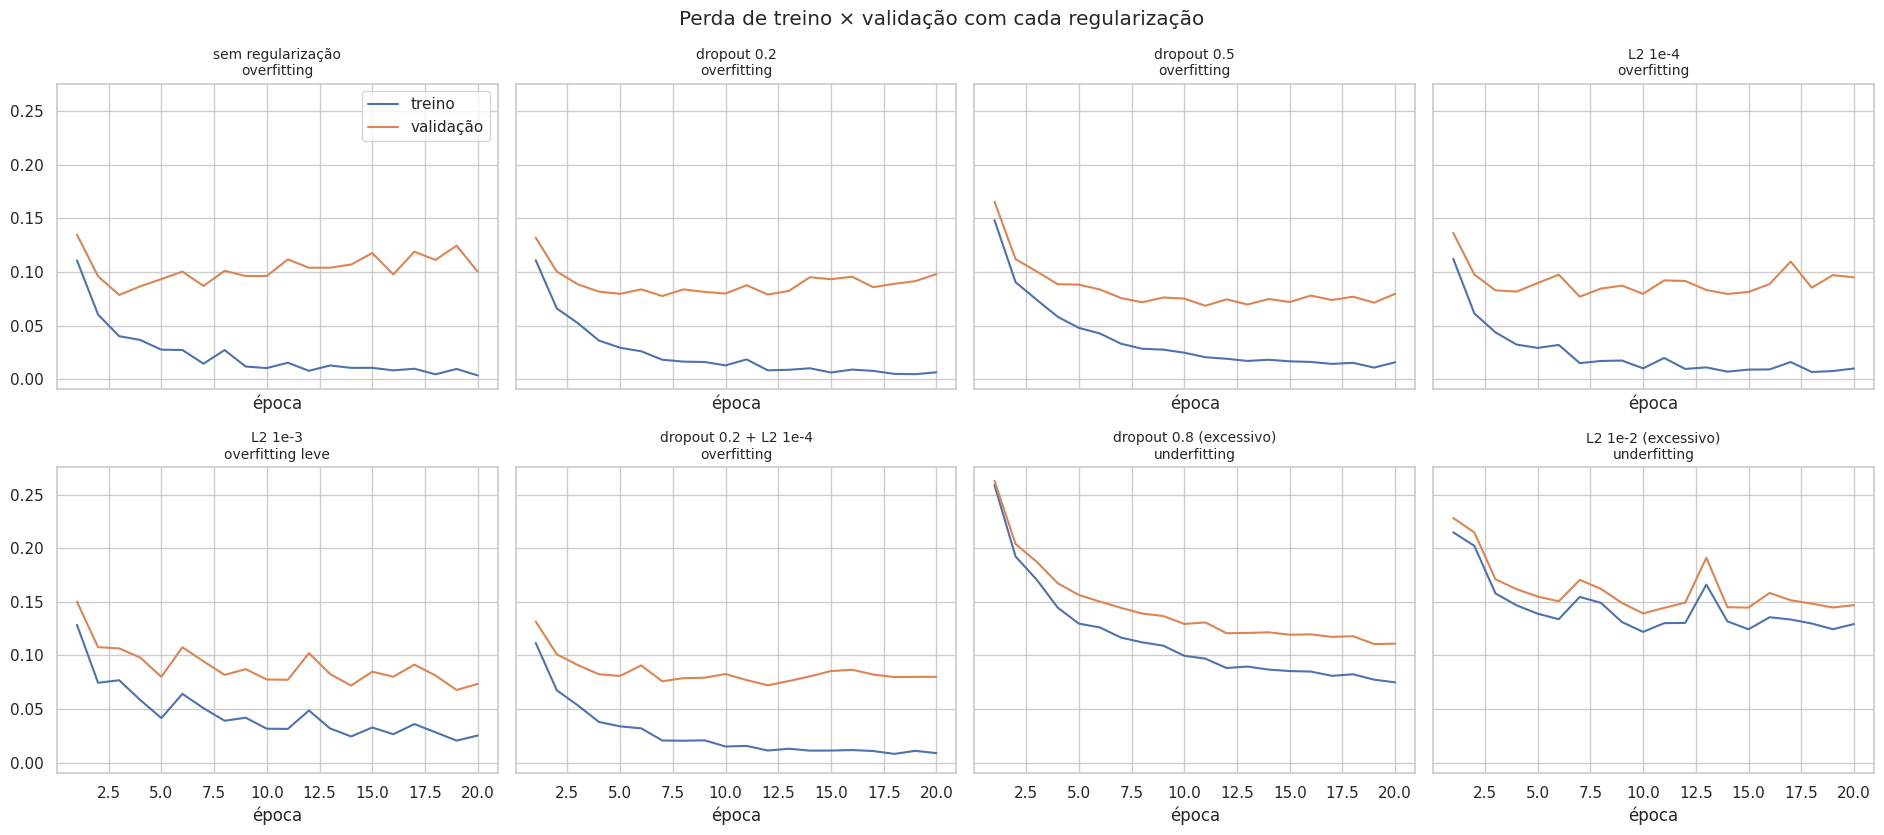

In [16]:
reg = dados("regularizacao")
colunas_acc = ["treino (%)", "validação (%)", "teste (%)"]
fig, ax = plt.subplots(figsize=(14, 5))
posicoes = np.arange(len(reg))
for deslocamento, coluna in zip([-0.27, 0, 0.27], colunas_acc):
    ax.bar(posicoes + deslocamento, reg[coluna], 0.27, label=coluna.replace(" (%)", ""))
ax.set_xticks(posicoes, list(reg["experimento"]), rotation=20, ha="right")
ax.set_ylim(reg[colunas_acc].min().min() - 0.5, 100.2)
ax.set(ylabel="acurácia (%)", title="Treino × validação × teste por regularização")
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(19, 8.5), sharex=True, sharey=True)
for ax, r in zip(axes.flatten(), do_grupo("regularizacao")):
    ax.plot(r["historico"]["epoca"], r["historico"]["perda_treino"], label="treino")
    ax.plot(r["historico"]["epoca"], r["historico"]["perda_validacao"], label="validação")
    ax.set_title(f"{r['nome']}\n{r['diagnostico']}", fontsize=10)
    ax.set_xlabel("época")
axes[0, 0].legend()
fig.suptitle("Perda de treino × validação com cada regularização")
plt.tight_layout()
plt.show()

**Como ler os gráficos:**

- **Barras:** acurácia de treino, validação e teste de cada versão. Barra de treino bem mais alta que as outras indica overfitting; as três baixas indicam underfitting. O eixo começa perto da menor acurácia, para as diferenças ficarem visíveis.
- **Curvas:** perda de treino e de validação a cada época, uma versão por quadro, todas na mesma escala e com o diagnóstico no título. Quanto menor a perda, melhor; quanto mais as duas linhas se afastam, mais a rede está decorando.

## Conclusão do tópico 4

- **Sem regularização, a rede decora.** O fundo do "U" da perda de validação fica na época 3, e a perda de treino vai quase a zero: a rede passa a saber o treino "de cor".
- **A regularização moderada adia e reduz a memorização.** Com dropout ou L2, o fundo do "U" passa para as épocas 7 a 19, e a perda sobe menos depois dele. O dropout de 50% é o exemplo mais claro: a perda de validação fica estável até o fim. Na prática, a rede fica menos "convencida" dos próprios erros, e as probabilidades que ela dá ficam mais confiáveis.
- **Mas a regularização não aumentou os acertos.** Todas as versões moderadas ficaram empatadas com a versão sem regularização (97,91% a 98,12%, contra 98,13%). Com 50 mil exemplos de treino, a rede já generaliza bem, e boa parte dos erros que sobram vem de dígitos ambíguos (tópico 5), não de memorização. Regularizar não ensina a rede a ler um 4 que parece um 9.
- **Em excesso, vira underfitting.** Com dropout de 80% ou L2 forte (0,01), a rede não aprende nem o treino (97,9% e 96,6% de acerto). O L2 forte tem gap quase zero (0,13 pp), mas porque vai mal nos dois conjuntos: **gap pequeno, sozinho, não significa modelo bom.**
- **Modelo final:** pela regra, a versão **sem regularização** (98,13% na validação). A combinação **dropout 20% + L2 0,0001** empata (98,12%) e tem uma perda de validação bem mais estável. Seria uma escolha igualmente válida, e mais segura se o treino fosse mais longo.

# 5. Avaliação

**Por que este tópico?** As acurácias mostram **quanto** cada rede acerta; a avaliação mostra **onde** ela erra. Para os 33 experimentos, apresentamos:

1. a acurácia de treino × teste e os erros mais frequentes;
2. a **matriz de confusão** no teste;
3. os erros que se repetem em todas as configurações;
4. a análise detalhada do modelo final.

O baseline e a MLP 1×128 têm a mesma configuração e a mesma semente e produziram resultados idênticos; por isso, o baseline aparece apenas na tabela.

,experimento,treino (%),validação (%),teste (%),gap treino−teste (pp),principais confusões (real→previsto),diagnóstico
0,baseline 1×128,99.59,97.29,97.61,1.98,"5→3 (20), 4→9 (18), 9→7 (9)",overfitting
1,MLP 1×64,99.75,97.24,97.46,2.29,"5→3 (18), 4→9 (15), 8→0 (12)",overfitting
2,MLP 1×128,99.59,97.29,97.61,1.98,"5→3 (20), 4→9 (18), 9→7 (9)",overfitting
3,MLP 1×256,99.85,97.88,97.95,1.90,"9→4 (12), 2→7 (9), 2→8 (9)",overfitting
4,MLP 1×512,99.61,97.82,97.97,1.64,"4→9 (16), 7→9 (11), 9→4 (11)",overfitting
5,MLP 2×64,99.55,97.20,97.25,2.30,"4→9 (30), 5→3 (17), 6→4 (12)",overfitting
6,MLP 2×128,99.73,97.77,97.66,2.07,"4→9 (16), 7→9 (12), 3→9 (11)",overfitting
7,MLP 2×256,99.62,97.78,97.97,1.65,"4→9 (17), 5→3 (13), 2→7 (12)",overfitting
8,MLP 2×512,99.73,97.94,98.00,1.73,"4→9 (12), 9→7 (11), 2→7 (10)",overfitting
9,MLP 3×64,99.61,97.42,97.45,2.16,"7→2 (14), 9→4 (13), 4→9 (11)",overfitting


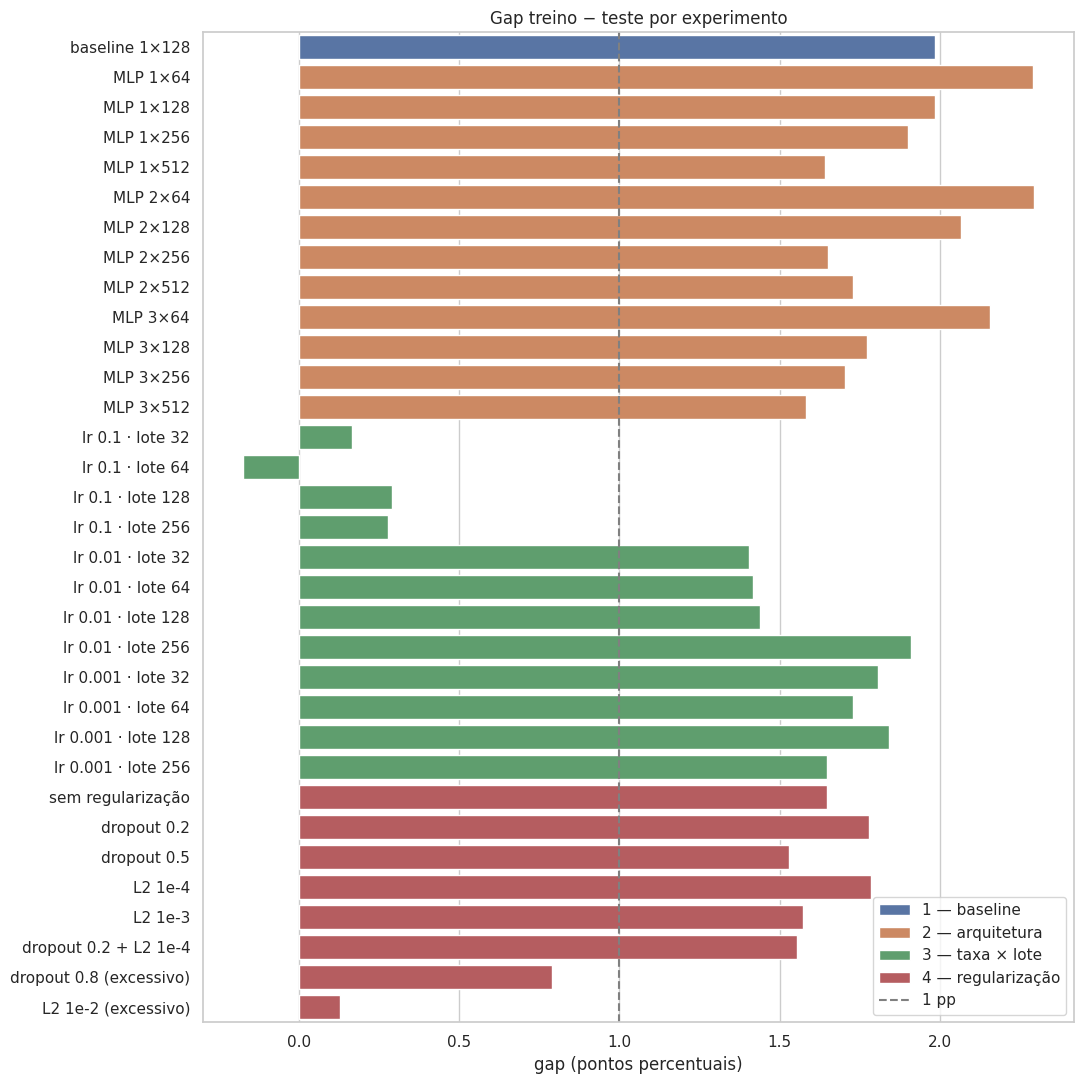

In [17]:
todos = dados()
display(todos[["experimento", "treino (%)", "validação (%)", "teste (%)", "gap treino−teste (pp)",
               "principais confusões (real→previsto)", "diagnóstico"]].round(DECIMAIS))

NOMES_GRUPOS = {"base": "1 — baseline", "arquitetura": "2 — arquitetura",
                "treinamento": "3 — taxa × lote", "regularizacao": "4 — regularização"}
fig, ax = plt.subplots(figsize=(11, 11))
sns.barplot(data=todos.assign(tópico=todos["grupo"].map(NOMES_GRUPOS)),
            y="experimento", x="gap treino−teste (pp)", hue="tópico", dodge=False, ax=ax)
ax.axvline(100 * LIMIAR_GAP, color="gray", linestyle="--", label="1 pp")
ax.set(title="Gap treino − teste por experimento", xlabel="gap (pontos percentuais)", ylabel="")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Como ler:** na tabela, a coluna "principais confusões" lista os 3 erros mais frequentes de cada experimento, no formato real → previsto (quantidade). Por exemplo, `4→9 (12)` significa que 12 imagens de "4" foram lidas como "9". No gráfico, cada barra é o gap treino − teste de um experimento, em pp, e a linha tracejada marca 1 pp. Barras longas indicam memorização.

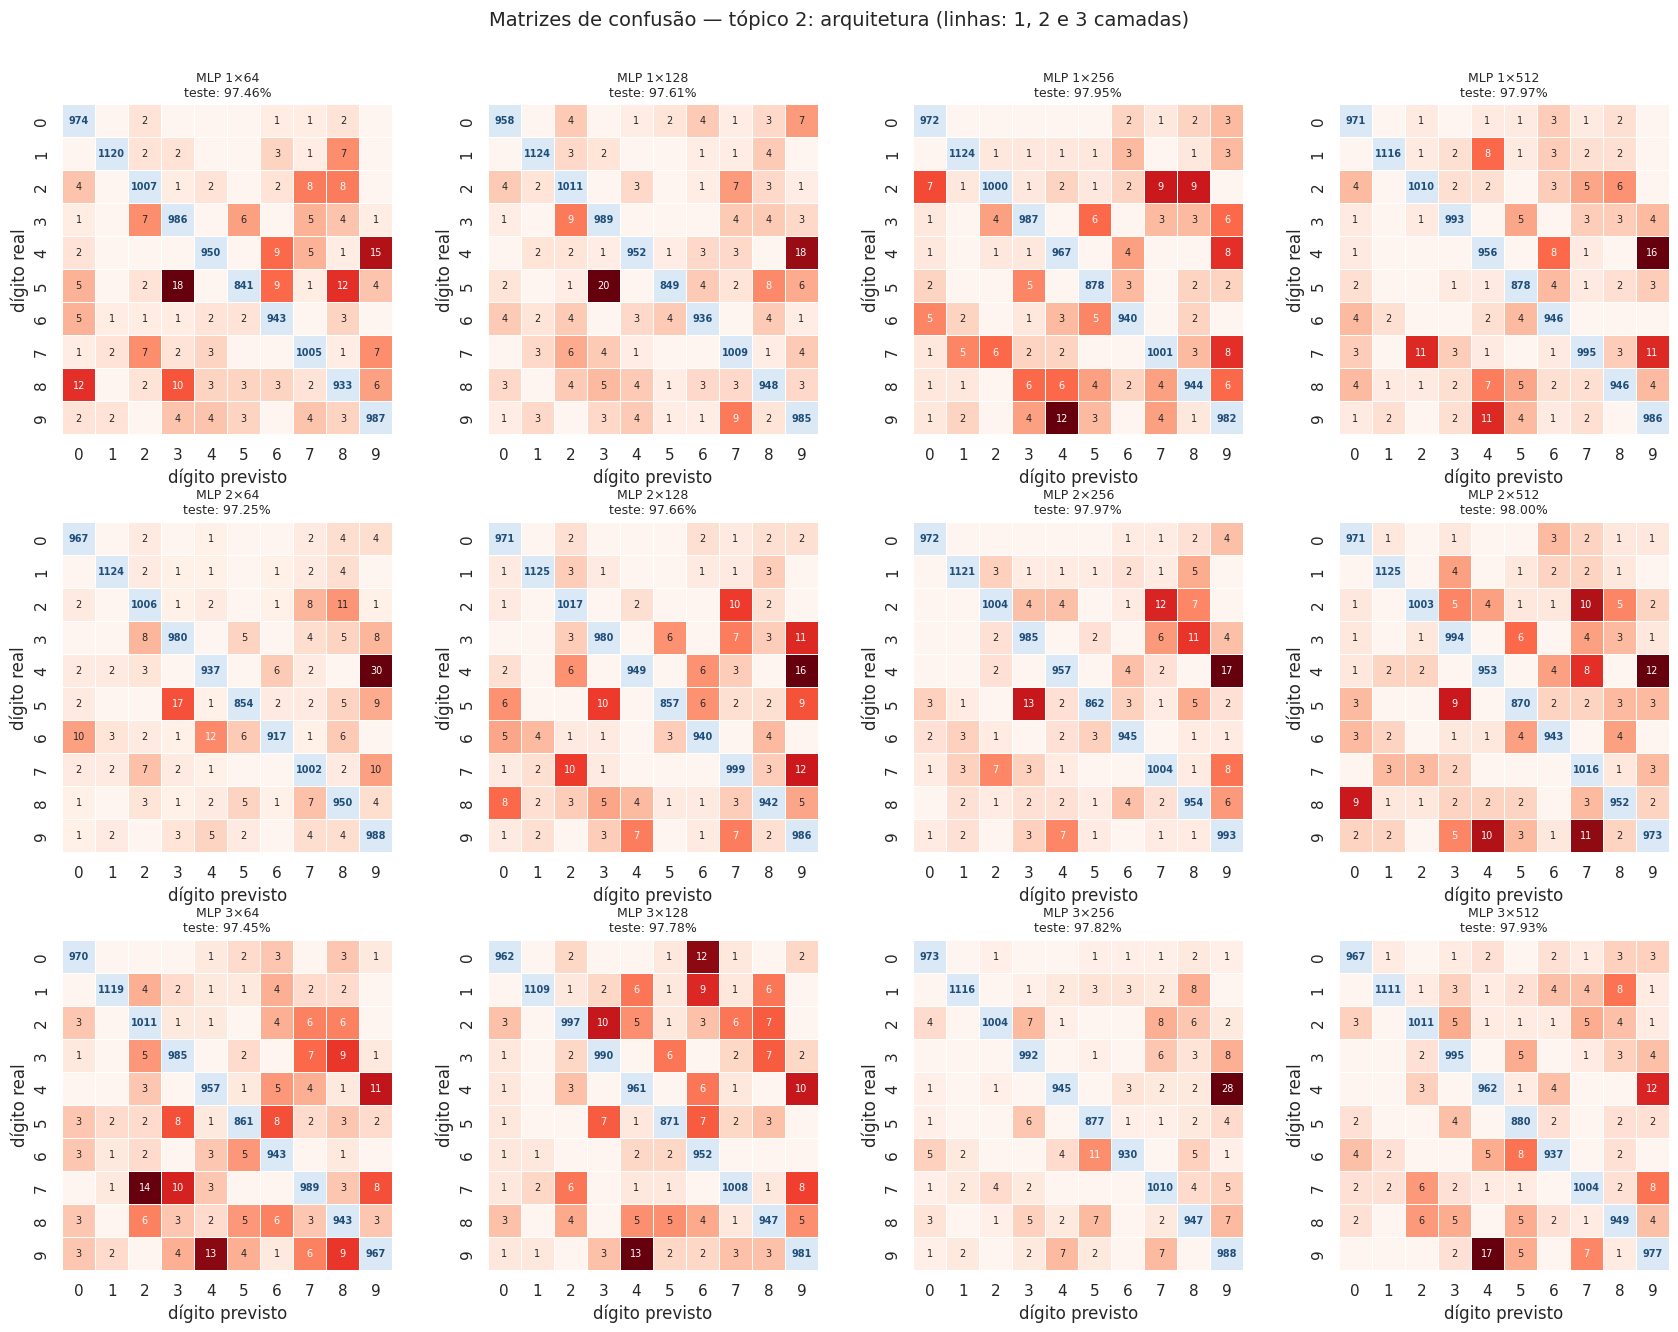

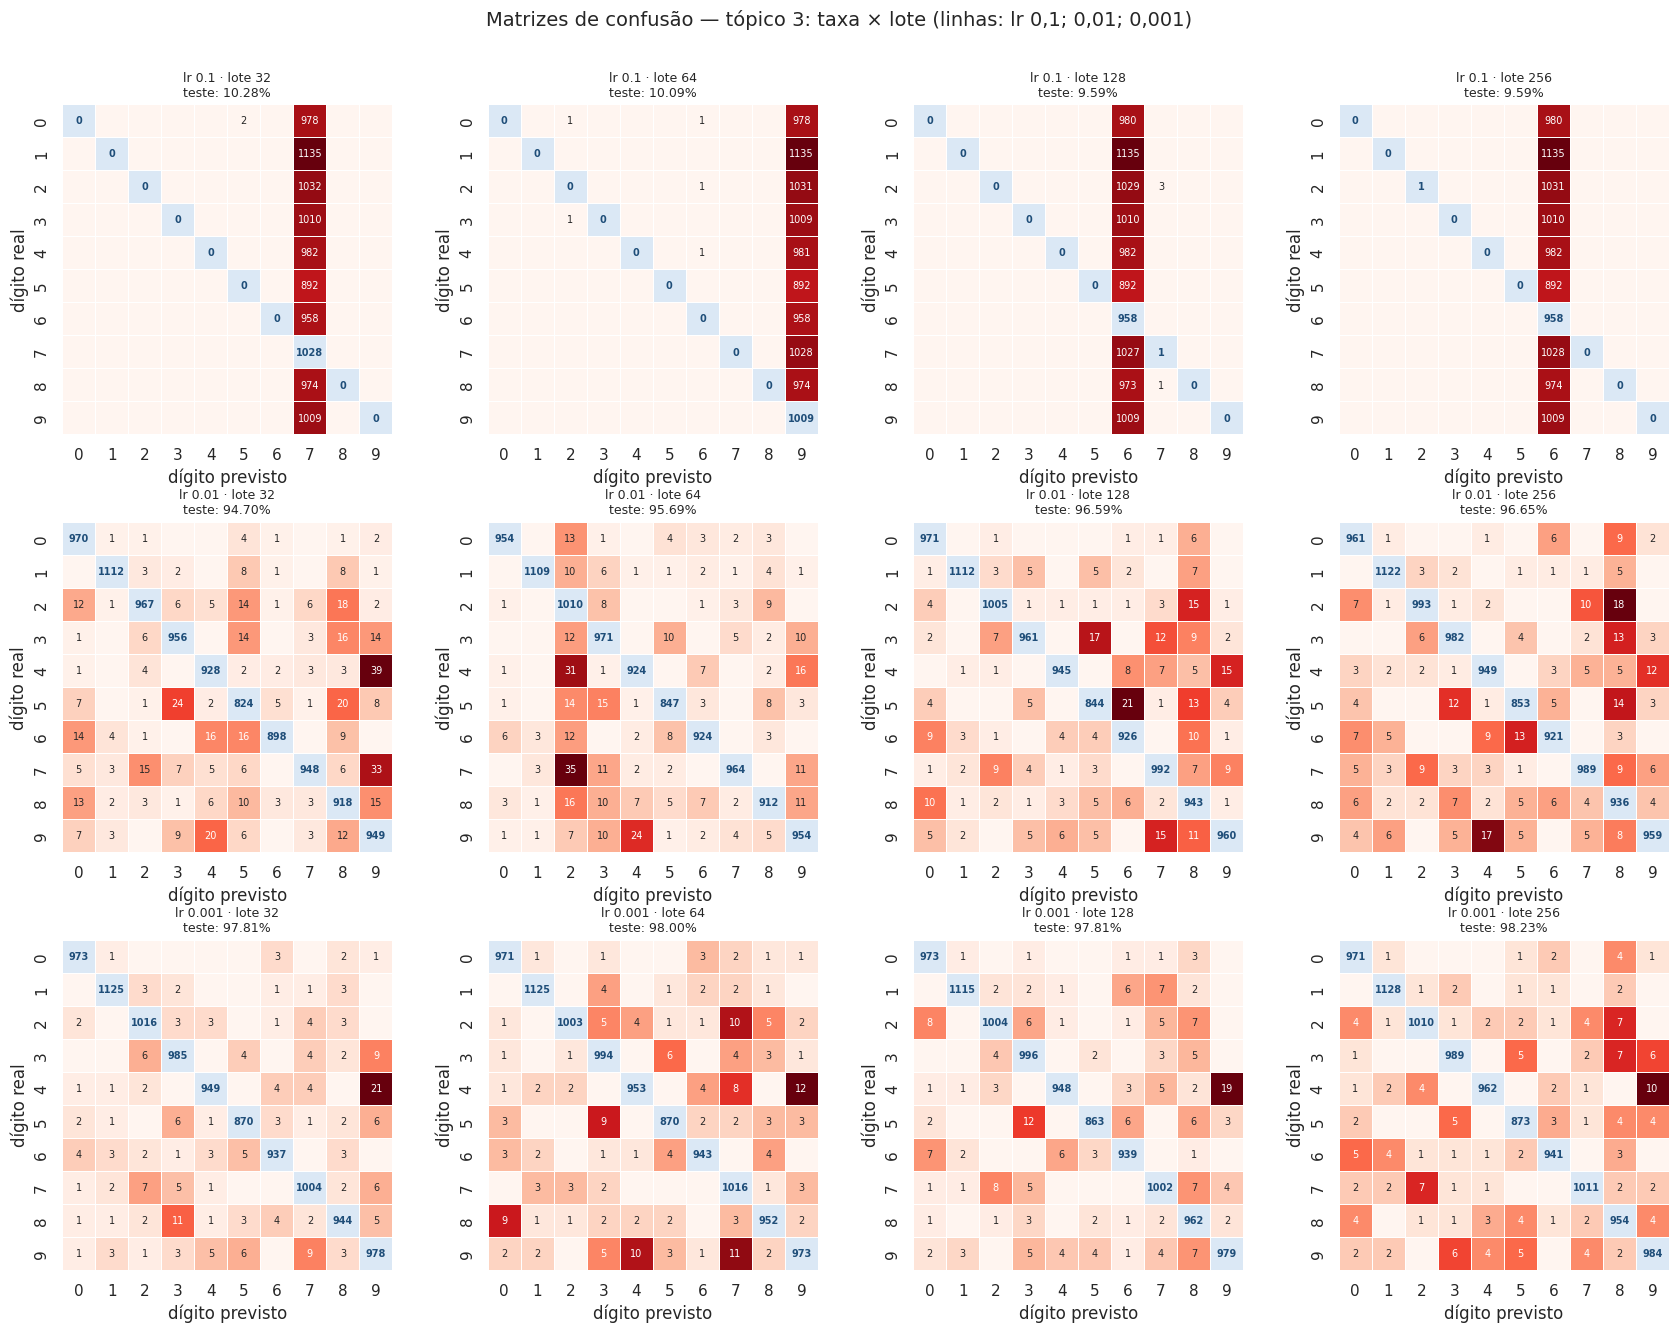

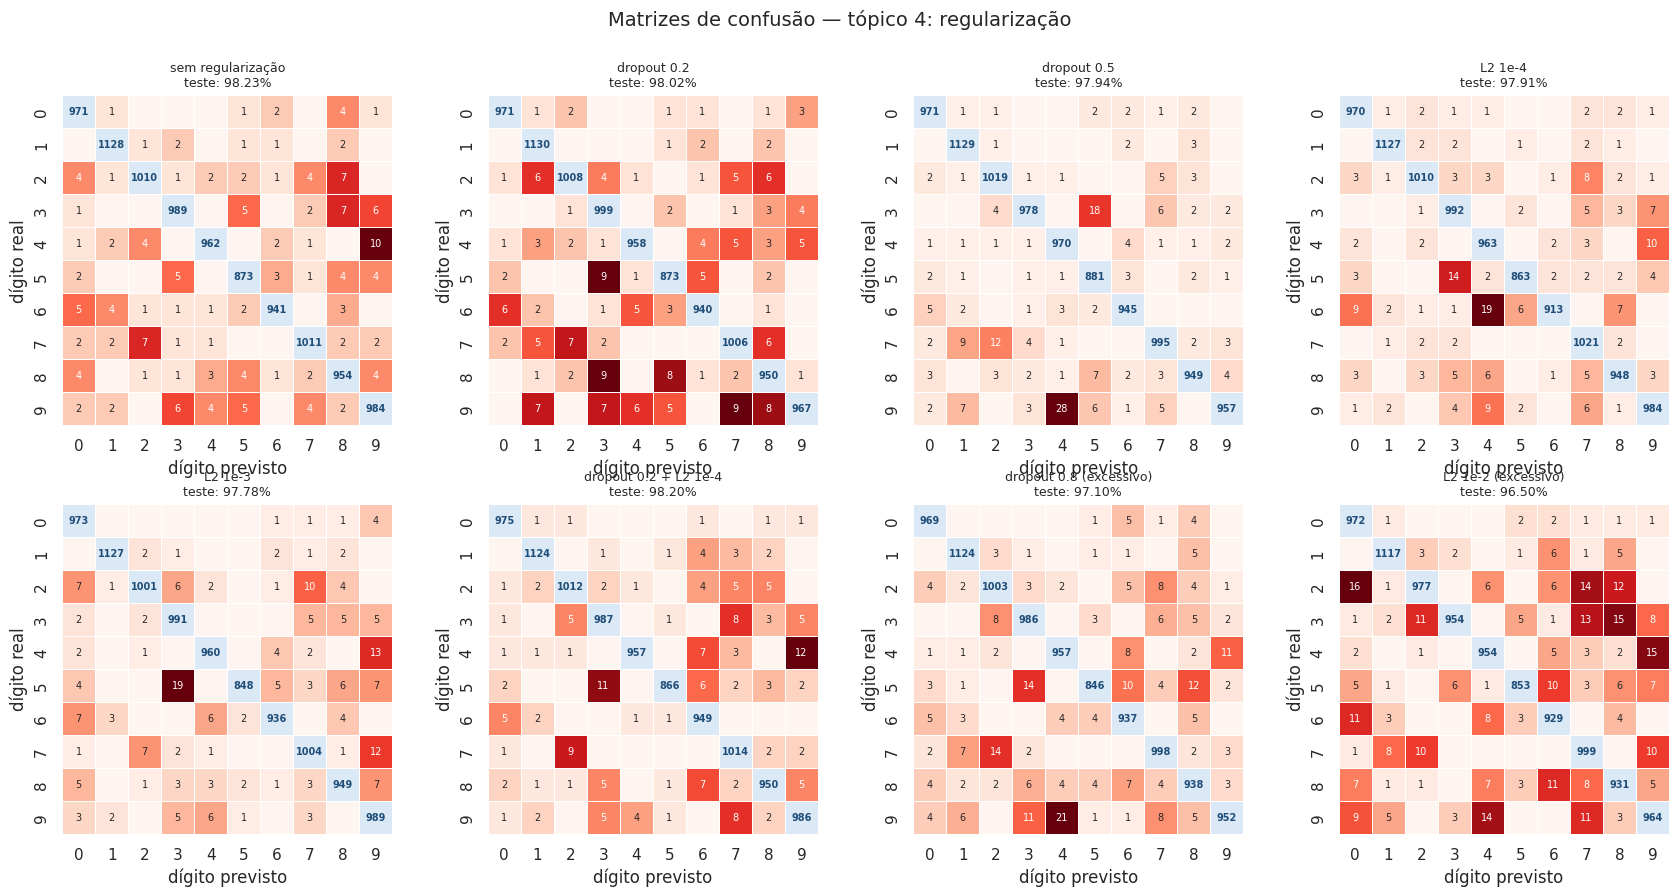

In [18]:
plotar_grade_matrizes(do_grupo("arquitetura"), "Matrizes de confusão — tópico 2: arquitetura (linhas: 1, 2 e 3 camadas)")
plotar_grade_matrizes(do_grupo("treinamento"), "Matrizes de confusão — tópico 3: taxa × lote (linhas: lr 0,1; 0,01; 0,001)")
plotar_grade_matrizes(do_grupo("regularizacao"), "Matrizes de confusão — tópico 4: regularização")

**Como ler as matrizes de confusão:** cada linha é o dígito real e cada coluna, o dígito previsto. Na diagonal, em azul, estão os acertos de cada dígito. Fora dela, em vermelho, estão os erros: a célula da linha 4 com a coluna 9 conta quantos "4" foram lidos como "9". Quanto mais escuro o vermelho, mais frequente o erro. Nas redes com taxa 0,1, todas as imagens caem em uma única coluna, a confirmação visual de que elas "chutam" sempre o mesmo dígito.

## Erros que se repetem

Para separar os erros típicos do MNIST dos erros de uma configuração específica, somamos as matrizes de confusão. Entram **28 dos 33 experimentos**. Ficam de fora os 5 com menos de 95% de acerto no teste: os quatro com taxa 0,1, que respondem sempre o mesmo dígito, e o de taxa 0,01 com lote 32 (94,7%). Os erros deles vêm de um treino que falhou, não da dificuldade de cada dígito, e distorceriam a soma.

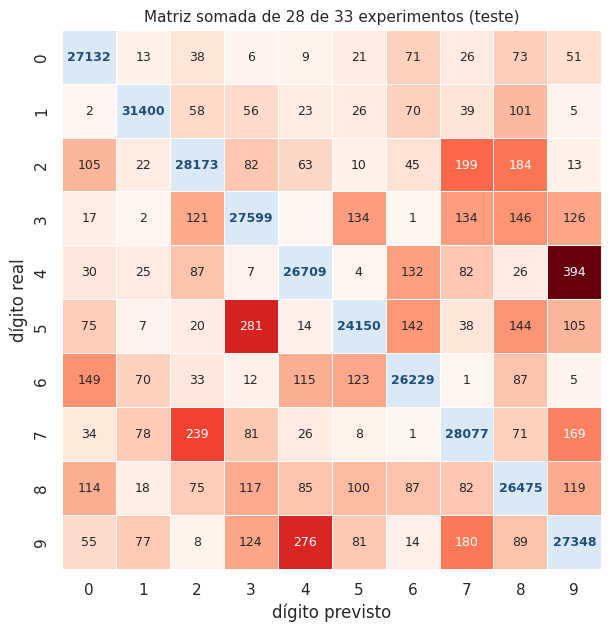

,par de dígitos,erros somados,sentido mais comum,experimentos com o par entre os 3 erros mais comuns (de 28)
0,4 e 9,670,4 lido como 9 (394),26
1,2 e 7,438,7 lido como 2 (239),12
2,3 e 5,415,5 lido como 3 (281),13
3,7 e 9,349,9 lido como 7 (180),9
4,5 e 6,265,5 lido como 6 (142),3


In [19]:
validos = [r for r in RESULTADOS.values() if r["acc_teste"] >= 0.95]
matriz_somada = np.sum([r["matriz"] for r in validos], axis=0)
fig, ax = plt.subplots(figsize=(8, 7))
plotar_matriz_confusao(matriz_somada, f"Matriz somada de {len(validos)} de {len(RESULTADOS)} experimentos (teste)", ax, fonte=9)
plt.show()

erros = matriz_somada.copy()
np.fill_diagonal(erros, 0)
presenca = Counter(
    par for r in validos
    for par in {tuple(sorted((real, prev))) for real, prev, _ in principais_confusoes(r["matriz"], 3)}
)
pares = sorted(((erros[a, b] + erros[b, a], a, b) for a in range(10) for b in range(a + 1, 10)), reverse=True)[:5]
display(pd.DataFrame([
    {
        "par de dígitos": f"{a} e {b}",
        "erros somados": int(total),
        "sentido mais comum": (f"{a} lido como {b} ({erros[a, b]})" if erros[a, b] >= erros[b, a]
                               else f"{b} lido como {a} ({erros[b, a]})"),
        f"experimentos com o par entre os 3 erros mais comuns (de {len(validos)})": presenca[(a, b)],
    }
    for total, a, b in pares
]))

**Como ler a tabela:** cada linha é um par de dígitos que a rede confunde, nos dois sentidos (por exemplo, 4 lido como 9 **e** 9 lido como 4).

- **erros somados:** total de confusões entre os dois dígitos nos 28 experimentos;
- **sentido mais comum:** qual das duas trocas acontece mais;
- **experimentos com o par entre os 3 erros mais comuns:** em quantos dos 28 experimentos esse par está entre os 3 erros mais frequentes. Quanto maior o número, mais o erro independe da configuração da rede.

## Modelo final

O modelo final erra **177 de 10.000 imagens (98,23% de acerto)**: 62 erros a menos que o baseline, uma redução de 26%. Em outras palavras, erra 1 a cada 56 dígitos.

Para cada dígito, o relatório abaixo mostra:

- **precisão:** quando a rede diz "8", com que frequência é mesmo um 8;
- **recall:** de todos os 8 reais, quantos a rede encontrou;
- **F1:** combina precisão e recall em um único número, que só é alto se os dois forem altos.

Por último, aparecem os 20 erros em que a rede estava **mais segura** da resposta errada.

Modelo final: 2 camadas × 512 neurônios | lr 0.001 | lote 256 | dropout 0 | L2 0
Treino 99.88% | validação 98.13% | teste 98.23% | +0.62 pp em relação ao baseline


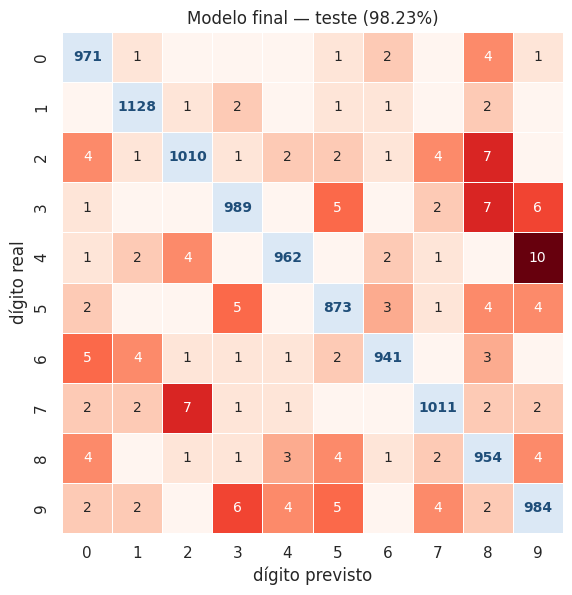

,precisão,recall,F1,imagens
dígito,,,,
8,0.9685,0.9795,0.9740,974
9,0.9733,0.9752,0.9743,1009
5,0.9776,0.9787,0.9782,892
3,0.9831,0.9792,0.9812,1010
2,0.9863,0.9787,0.9825,1032
4,0.9887,0.9796,0.9841,982
0,0.9788,0.9908,0.9848,980
7,0.9863,0.9835,0.9849,1028
6,0.9895,0.9823,0.9859,958


Erros do modelo final no teste: 177 de 10,000 imagens


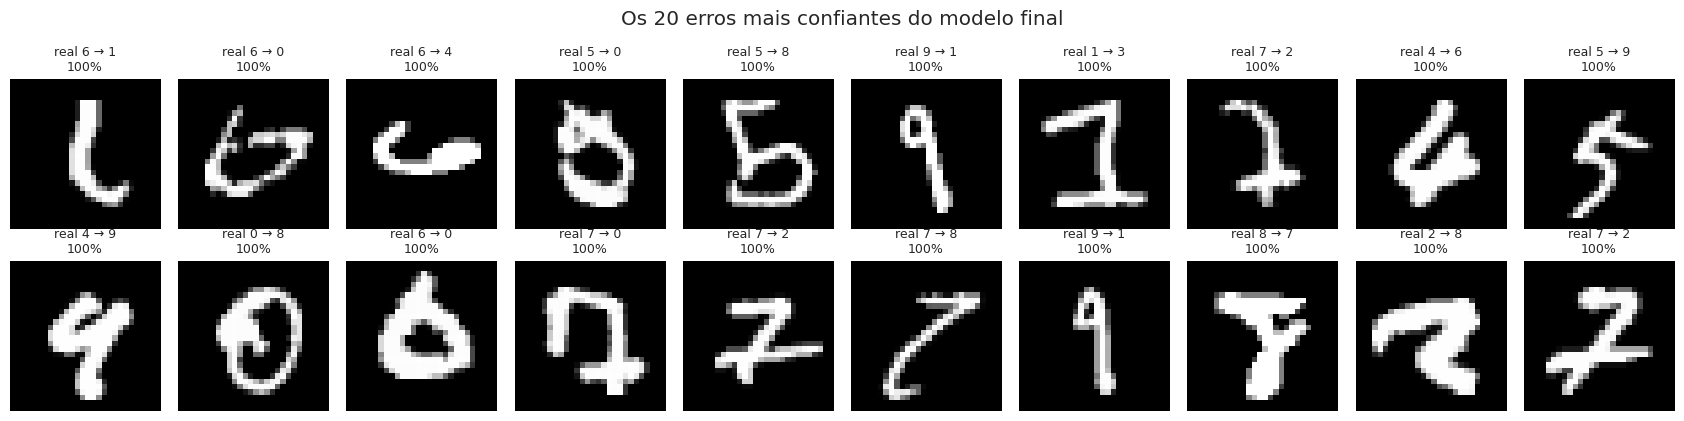

In [20]:
print(f"Modelo final: {modelo_final['camadas_ocultas']} camadas × {modelo_final['neuronios']} neurônios | "
      f"lr {modelo_final['taxa_aprendizado']:g} | lote {modelo_final['tamanho_lote']} | "
      f"dropout {modelo_final['dropout']:g} | L2 {modelo_final['weight_decay']:g}")
print(f"Treino {modelo_final['acc_treino']:.2%} | validação {modelo_final['acc_validacao']:.2%} | "
      f"teste {modelo_final['acc_teste']:.2%} | {100 * (modelo_final['acc_teste'] - baseline['acc_teste']):+.2f} pp "
      f"em relação ao baseline")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
plotar_matriz_confusao(modelo_final["matriz"], f"Modelo final — teste ({modelo_final['acc_teste']:.2%})", ax, fonte=10)
plt.show()

modelo = modelo_final["modelo"]
modelo.eval()
with torch.no_grad():
    probabilidades = torch.softmax(modelo(X_teste), dim=1).cpu()
previsto = probabilidades.argmax(dim=1)
real = y_teste.cpu()

relatorio = classification_report(real.numpy(), previsto.numpy(), output_dict=True)
relatorio = pd.DataFrame({k: v for k, v in relatorio.items() if k.isdigit()}).T
relatorio = relatorio.rename(columns={"precision": "precisão", "f1-score": "F1", "support": "imagens"})
relatorio.index.name = "dígito"
relatorio["imagens"] = relatorio["imagens"].astype(int)
display(relatorio.round(4).sort_values("F1"))

erradas = torch.where(previsto != real)[0]
confianca = probabilidades[erradas, previsto[erradas]]
mais_confiantes = erradas[torch.argsort(confianca, descending=True)][:20]
print(f"Erros do modelo final no teste: {len(erradas)} de {len(real):,} imagens")
fig, axes = plt.subplots(2, 10, figsize=(17, 4.4))
for ax in axes.flatten():
    ax.axis("off")
for ax, idx in zip(axes.flatten(), mais_confiantes):
    ax.imshow(X_teste_bruto[idx].numpy(), cmap="gray")
    ax.set_title(f"real {real[idx].item()} → {previsto[idx].item()}\n{probabilidades[idx, previsto[idx]].item():.0%}",
                 fontsize=9)
fig.suptitle("Os 20 erros mais confiantes do modelo final")
plt.tight_layout()
plt.show()

## Conclusão do tópico 5

- **Treino × teste:** em todos os modelos que aprenderam, o treino fica de 1,4 a 2,3 pp acima do teste, a marca da memorização vista nos tópicos 2 a 4. Só a regularização excessiva aproxima os dois, e à custa de acertos. Nas redes com taxa 0,1, o gap é zero porque treino e teste estão no nível do chute (~10%).
- **Os erros são quase sempre os mesmos.** O par **4 e 9** está entre os 3 erros mais comuns em **26 dos 28** experimentos (670 confusões somadas), seguido de **2 e 7**, **3 e 5** e **7 e 9**. São dígitos que diferem por poucos traços: o topo aberto ou fechado do 4 e do 9, a base do 2 e do 7, a metade de cima do 3 e do 5.
- **Modelo final:** os dígitos mais difíceis são o 8 e o 9 (F1 de 0,974). O 8 tem a menor precisão, ou seja, a rede tende a chamar outros dígitos de 8. O mais fácil é o 1 (F1 de 0,992), de traço simples.
- **Erros "com certeza":** os 20 erros mais confiantes têm cerca de 100% de certeza, e vários seriam difíceis até para uma pessoa: um 6 que parece um "l", um 7 cortado que parece um 2, um 0 com um traço dentro que lembra um 8. Isso mostra dois limites. A MLP olha os pixels como uma lista, sem noção de forma. E o modelo sem regularização fica confiante demais, o mesmo efeito que faz a perda de validação subir no overfitting.

# 6. Análise Crítica

A célula abaixo reúne as evidências usadas nas respostas.

In [21]:
print("Cinco maiores acurácias de validação:")
display(dados().sort_values("validação (%)", ascending=False)
        [["experimento", "validação (%)", "teste (%)", "parâmetros"]].head(5).round(DECIMAIS))
print(f"Régua de ruído: {2 * RUIDO_PP:.2f} pp")

print("\nDiagnósticos por tópico:")
display(pd.crosstab(todos["grupo"].map(NOMES_GRUPOS).rename("tópico"), todos["diagnóstico"]))

print("\nSaturação — ganho na validação (pp) ao dobrar a largura (cada coluna em relação à anterior):")
grade_val = arq.pivot(index="camadas", columns="neurônios", values="validação (%)")
display(grade_val.diff(axis=1).round(2))
print("Saturação — ganho na validação (pp) ao adicionar uma camada (cada linha em relação à anterior):")
display(grade_val.diff(axis=0).round(2))

print(f"\nTempo total de execução: {(time.time() - INICIO_NOTEBOOK) / 60:.1f} minutos")

Cinco maiores acurácias de validação:


,experimento,validação (%),teste (%),parâmetros
25,sem regularização,98.13,98.23,669706
24,lr 0.001 · lote 256,98.13,98.23,669706
30,dropout 0.2 + L2 1e-4,98.12,98.20,669706
26,dropout 0.2,98.05,98.02,669706
27,dropout 0.5,98.05,97.94,669706


Régua de ruído: 0.52 pp

Diagnósticos por tópico:


diagnóstico,não convergiu,overfitting,overfitting leve,underfitting
tópico,,,,
1 — baseline,0,1,0,0
2 — arquitetura,0,12,0,0
3 — taxa × lote,4,5,1,2
4 — regularização,0,5,1,2



Saturação — ganho na validação (pp) ao dobrar a largura (cada coluna em relação à anterior):


neurônios,64,128,256,512
camadas,,,,
1,NaN,0.05,0.59,-0.06
2,NaN,0.57,0.01,0.16
3,NaN,0.10,0.30,0.01


Saturação — ganho na validação (pp) ao adicionar uma camada (cada linha em relação à anterior):


neurônios,64,128,256,512
camadas,,,,
1,NaN,NaN,NaN,NaN
2,-0.04,0.48,-0.10,0.12
3,0.22,-0.25,0.04,-0.11



Tempo total de execução: 11.9 minutos


## Qual configuração apresentou melhor desempenho?

A **MLP com 2 camadas de 512 neurônios, treinada com Adam (taxa 0,001) em lotes de 256 imagens e sem regularização**: 98,13% na validação e **98,23% no teste**, +0,62 pp sobre o baseline. Porém, as cinco melhores configurações ficam a no máximo 0,08 pp umas das outras, bem abaixo da régua de ruído (0,52 pp): é um empate técnico. O que realmente fez diferença foram **duas escolhas**: largura de pelo menos 256 neurônios e taxa de aprendizado de 0,001.

## Houve overfitting? Como foi identificado?

Sim, em todos os modelos sem regularização treinados com taxa 0,001, incluindo o final. Dois sinais independentes mostraram isso:

1. **Gap:** acerto de 99,5% a 99,9% no treino, contra 97,25% a 98,23% no teste (1,6 a 2,3 pp).
2. **Curva em "U" da perda de validação:** o erro em dados novos atingiu o mínimo entre as épocas 3 e 8 e depois subiu de 28% a 88% até a época 20, enquanto o erro no treino continuava caindo.

A regularização moderada adiou e reduziu esse efeito; a excessiva trocou o overfitting por underfitting.

## Qual combinação de hiperparâmetros foi mais estável?

**Taxa 0,001 com lote 256:** teve a menor oscilação entre épocas (0,165 pp) e o menor ruído entre lotes (0,011) entre as combinações que convergiram. A regra geral ficou clara: **quanto menor a taxa e maior o lote, mais estável o treino**. A taxa 0,1 divergiu, e a 0,01 oscilou até 0,76 pp com lote 32.

## Existe um ponto de saturação ao aumentar a complexidade da rede?

Sim, **por volta de 256 neurônios (~200 mil parâmetros)**. Até esse ponto, aumentar a largura trouxe ganhos acima da régua de ruído. Depois dele, os ganhos ficaram entre −0,06 e +0,16 pp, e camadas extras não trouxeram ganho. A MLP 3×512, com 932 mil parâmetros (4,6 vezes mais que a 1×256), acertou 97,83% na validação, contra 97,88% da 1×256: mais custo e memorização mais cedo, sem ganho. A partir daí, o limite deixa de ser o tamanho da rede e passa a ser o tipo de rede, porque ao achatar a imagem a MLP perde a noção de forma.

# Conclusão

## O que foi feito

| Tópico | O que fizemos | Resultado |
|---|---|---|
| **1. Implementação base** | Preparamos o MNIST e treinamos uma MLP 1×128 como referência | 97,61% no teste, já com sinais de overfitting; régua de ruído de 0,52 pp |
| **2. Arquitetura** | 12 redes, de 1 a 3 camadas e de 64 a 512 neurônios | A largura ajuda até ~256 neurônios; a profundidade não ajudou |
| **3. Treinamento** | 12 combinações de taxa de aprendizado e tamanho do lote | A taxa 0,001 é essencial; o lote 256 foi o mais estável e um dos mais rápidos |
| **4. Regularização** | Dropout e L2, em doses moderadas e excessivas | Adiam a memorização, mas não aumentam os acertos; em excesso, causam underfitting |
| **5. Avaliação** | Matrizes de confusão e erros de todos os experimentos | Os erros se concentram em pares parecidos: 4 e 9, 2 e 7, 3 e 5 |

## Resultado da escolha

O modelo final é uma **MLP 2×512 treinada com Adam (taxa 0,001) em lotes de 256 imagens: 98,23% de acerto no teste, ou 177 erros em 10.000 imagens**, 26% menos erros que o baseline. Ele foi escolhido pela validação, sem consultar o teste, e o resultado no teste confirma a escolha.

## Causas e consequências

| O que observamos | Causa | Consequência |
|---|---|---|
| A taxa 0,1 fez a rede divergir | Passos grandes demais para a rede encontrar o caminho | A taxa de aprendizado é a primeira coisa a acertar: errar custou até 88 pp |
| Redes maiores param de melhorar a partir de ~256 neurônios | A MLP já extrai quase tudo o que os pixels achatados oferecem | Redes maiores só aumentam o custo e a memorização |
| Toda rede sem regularização decorou o treino | Muitos parâmetros (até 932 mil) para 50 mil exemplos | Mais épocas não ajudam; a regularização deixa a rede mais confiável |
| Os erros restantes são dígitos ambíguos | A MLP não enxerga forma, só pixels soltos | O próximo salto exige outro tipo de rede, não mais ajustes nesta |

## Aplicabilidade

Um modelo como este resolve um problema real: **ler números escritos à mão em documentos digitalizados**, como CEPs em correspondências, valores em cheques, formulários e gabaritos. A leitura automática de cheques, aliás, foi uma das primeiras aplicações comerciais de redes neurais. Com 98,2% de acerto, o modelo pode automatizar a maior parte da leitura e mandar para revisão humana apenas os casos de baixa confiança. Antes do uso real, porém, a confiança precisa ser ajustada: os erros com ~100% de certeza mostram que, sem regularização, a rede não sabe quando está em dúvida.

Além do modelo, o processo vale para qualquer projeto de *machine learning*: partir de um baseline, escolher pela validação, medir o ruído antes de comemorar uma melhoria e conferir o overfitting nas curvas, não só na acurácia.

## Limitações e próximos passos

- **Busca sequencial:** cada tópico partiu da melhor escolha do anterior, então nem todas as combinações foram testadas.
- **Uma execução por configuração:** a régua de ruído reduz, mas não elimina, o efeito da sorte.
- **20 épocas fixas:** as versões mais lentas (taxa 0,01 e dropout de 80%) ainda estavam melhorando no fim.
- **Próximo passo natural: redes convolucionais (CNN).** Em vez de achatar a imagem, a CNN a analisa em pequenas janelas que percorrem a imagem inteira. Assim, ela preserva a vizinhança entre os pixels e reconhece traços e curvas em qualquer posição. Na aula de CNN, uma rede convolucional simples chegou a 99,25% no MNIST em 3 épocas, com um terço dos parâmetros da MLP final (comparação apenas indicativa, porque o treino da aula seguiu outro protocolo).